In [1]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 1: SETUP, LOAD DATA, AND SURVIVAL COHORT CHECK
# ============================================================

# Install lifelines for survival analysis
!pip -q install lifelines


# ------------------------------------------------------------
# IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from lifelines import (
    KaplanMeierFitter,
    CoxPHFitter,
    AalenJohansenFitter
)

from lifelines.statistics import logrank_test


# ------------------------------------------------------------
# UPLOAD MODELING BASE
# ------------------------------------------------------------

print("Upload: medimate_modeling_base.csv.gz\n")

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("\nUploaded file:", file_name)


# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(
    file_name,
    compression="gzip"
)

print("\nDATA LOADED")
print("Shape:", df.shape)


# ------------------------------------------------------------
# SHOW AVAILABLE COLUMNS
# ------------------------------------------------------------

print("\nAVAILABLE COLUMNS:\n")

for col in df.columns:
    print("-", col)


# ------------------------------------------------------------
# FIND THE SURVIVAL-TIME COLUMN
#
# We created survival_time_days_clean during cleaning.
# If that exact name is unavailable, check days_to_event.
# ------------------------------------------------------------

if "survival_time_days_clean" in df.columns:

    TIME_COL = "survival_time_days_clean"

elif "days_to_event" in df.columns:

    TIME_COL = "days_to_event"

else:

    raise ValueError(
        "No survival-time column found. "
        "Expected survival_time_days_clean or days_to_event."
    )


print(
    "\nSurvival time column:",
    TIME_COL
)


# ------------------------------------------------------------
# CHECK REQUIRED EVENT COLUMNS
# ------------------------------------------------------------

required_columns = [
    TIME_COL,
    "event_adverse",
    "event_transplant"
]

missing_required = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_required:

    raise ValueError(
        f"Missing required columns: {missing_required}"
    )


# ------------------------------------------------------------
# CREATE SURVIVAL COHORT
#
# Keep registrations with a valid,
# non-negative follow-up time.
# ------------------------------------------------------------

survival_df = df[
    df[TIME_COL].notna()
].copy()

survival_df = survival_df[
    survival_df[TIME_COL] >= 0
].copy()


# ------------------------------------------------------------
# CREATE EVENT TYPE
#
# 0 = no adverse/transplant event observed
#     during the available follow-up
#
# 1 = adverse event:
#     died or removed too sick
#
# 2 = transplant
#
# This lets us later perform competing-risk analysis.
# ------------------------------------------------------------

survival_df["event_type"] = 0

survival_df.loc[
    survival_df["event_adverse"] == 1,
    "event_type"
] = 1

survival_df.loc[
    (
        survival_df["event_adverse"] != 1
    )
    &
    (
        survival_df["event_transplant"] == 1
    ),
    "event_type"
] = 2


# ------------------------------------------------------------
# BINARY ADVERSE EVENT INDICATOR
#
# Used later for Kaplan-Meier / Cox modeling.
# Transplant and other endpoints are treated as
# non-adverse endpoints for this indicator.
# ------------------------------------------------------------

survival_df["adverse_event"] = (
    survival_df["event_type"] == 1
).astype(int)


# ------------------------------------------------------------
# BASIC QUALITY CHECKS
# ------------------------------------------------------------

print("\nSURVIVAL COHORT CREATED")

print(
    "Rows:",
    len(survival_df)
)

print(
    "Unique patients:",
    survival_df["PT_CODE"].nunique()
    if "PT_CODE" in survival_df.columns
    else "PT_CODE not available"
)

print(
    "\nFollow-up time summary:"
)

print(
    survival_df[TIME_COL]
    .describe()
    .round(2)
)


# ------------------------------------------------------------
# EVENT COUNTS
# ------------------------------------------------------------

event_labels = {
    0: "No adverse/transplant event",
    1: "Adverse event",
    2: "Transplant"
}

event_counts = (
    survival_df["event_type"]
    .value_counts()
    .sort_index()
    .rename(index=event_labels)
)

event_percent = (
    survival_df["event_type"]
    .value_counts(normalize=True)
    .sort_index()
    .rename(index=event_labels)
    * 100
)

event_summary = pd.DataFrame({
    "Count": event_counts,
    "Percent": event_percent
})

print("\nEVENT TYPE SUMMARY\n")

print(
    event_summary
    .round(2)
    .to_string()
)


# ------------------------------------------------------------
# CHECK ADVERSE / TRANSPLANT OVERLAP
#
# Ideally these should not both be 1
# for the same final waitlist endpoint.
# ------------------------------------------------------------

overlap_count = (
    (
        survival_df["event_adverse"] == 1
    )
    &
    (
        survival_df["event_transplant"] == 1
    )
).sum()

print(
    "\nRows marked as BOTH adverse and transplant:",
    overlap_count
)


# ------------------------------------------------------------
# CHECK FOLLOW-UP BY LISTING YEAR
# ------------------------------------------------------------

if "INIT_DATE" in survival_df.columns:

    survival_df["INIT_DATE"] = pd.to_datetime(
        survival_df["INIT_DATE"],
        errors="coerce"
    )

    survival_df["listing_year"] = (
        survival_df["INIT_DATE"].dt.year
    )

elif "listing_year" not in survival_df.columns:

    print(
        "\nNo INIT_DATE/listing_year available "
        "for year-level follow-up check."
    )


if "listing_year" in survival_df.columns:

    year_summary = (
        survival_df
        .groupby("listing_year")
        .agg(
            N=(TIME_COL, "size"),
            Median_Followup_Days=(
                TIME_COL,
                "median"
            ),
            Adverse_Events=(
                "adverse_event",
                "sum"
            )
        )
        .reset_index()
    )

    year_summary[
        "Adverse_Rate"
    ] = (
        year_summary["Adverse_Events"]
        / year_summary["N"]
    )

    print(
        "\nFOLLOW-UP BY LISTING YEAR\n"
    )

    print(
        year_summary
        .round(3)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\n==========================================")
print("CHUNK 1 COMPLETE")
print("==========================================")

print(
    "\nNext we will use Kaplan-Meier curves "
    "to study how waitlist risk changes over time."
)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Upload: medimate_modeling_base.csv.gz



Saving medimate_modeling_base.csv.gz to medimate_modeling_base.csv.gz

Uploaded file: medimate_modeling_base.csv.gz


/tmp/ipykernel_1271/3628853293.py:46: DtypeWarning: Columns (22,23,24,26,27,30) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(



DATA LOADED
Shape: (494862, 52)

AVAILABLE COLUMNS:

- ON_DIALYSIS
- A2A2B_ELIGIBILITY
- GENDER
- ABO
- BMI_TCR
- FUNC_STAT_TCR
- INIT_STAT
- INIT_CPRA
- END_CPRA
- REM_CD
- DAYSWAIT_CHRON
- END_STAT
- INIT_AGE
- DIALYSIS_DATE
- END_DATE
- INIT_DATE
- ETHCAT
- PT_CODE
- DAYSWAIT_ALLOC
- COMPOSITE_DEATH_DATE
- REGION
- WL_ID_CODE
- PREV_TX
- TX_DATE
- DON_TY
- DIAG_KI
- MULTIORG
- ORGAN
- PSTATUS
- PTIME
- TRR_ID_CODE
- DONOR_ID
- LISTING_CTR_CODE
- outcome
- event_adverse
- event_transplant
- censored
- days_to_event
- calculated_days_to_end
- invalid_date_order
- BMI_quality_flag
- BMI_TCR_clean
- FUNC_STAT_TCR_clean
- FUNC_STAT_invalid_flag
- listing_year
- INIT_CPRA_missing
- A2A2B_status
- BMI_missing
- FUNC_STAT_missing
- survival_valid
- survival_time_days_clean
- DAYSWAIT_CHRON_mismatch

Survival time column: survival_time_days_clean

SURVIVAL COHORT CREATED
Rows: 494803
Unique patients: 414130

Follow-up time summary:
count    494803.00
mean        649.54
std         654.24
mi

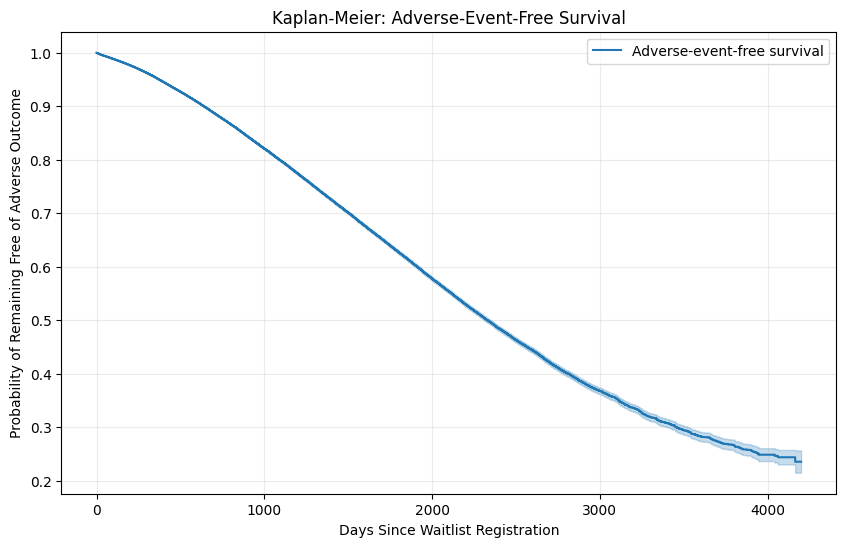

KAPLAN-MEIER SUMMARY

 Time_Days  Years  KM_Adverse_Free_Survival  KM_Implied_Adverse_Risk
       365      1                    0.9511                   0.0489
       730      2                    0.8809                   0.1191
      1095      3                    0.7989                   0.2011
      1825      5                    0.6214                   0.3786


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


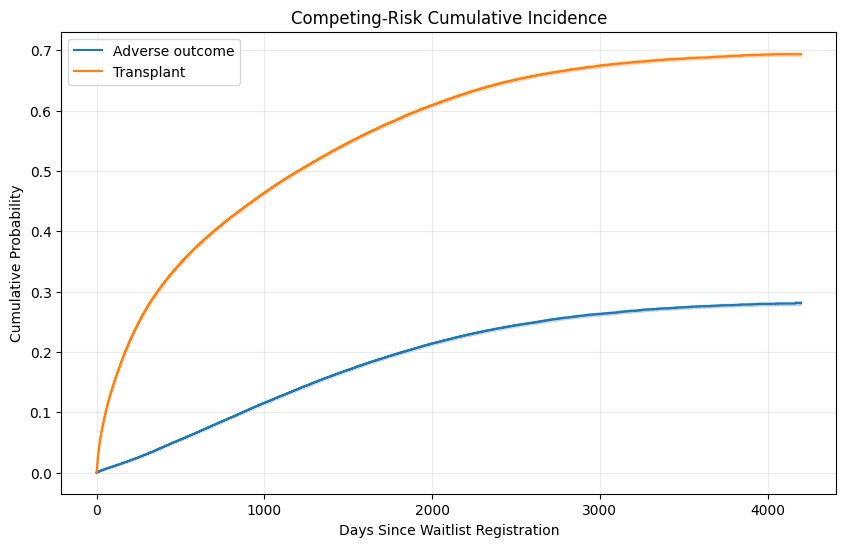


COMPETING-RISK SUMMARY

 Time_Days  Years  Adverse_Cumulative_Incidence  Transplant_Cumulative_Incidence  Still_Free_of_Both
       365      1                        0.0388                           0.3007              0.6605
       730      2                        0.0831                           0.4074              0.5096
      1095      3                        0.1268                           0.4815              0.3917
      1825      5                        0.2000                           0.5895              0.2105

KM VS COMPETING-RISK COMPARISON

 Years  KM_Implied_Adverse_Risk  Competing_Risk_Adverse_Incidence  KM_Minus_Competing_Risk
     1                   0.0489                            0.0388                   0.0101
     2                   0.1191                            0.0831                   0.0360
     3                   0.2011                            0.1268                   0.0743
     5                   0.3786                            0.2000       

In [2]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 2: OVERALL SURVIVAL + COMPETING RISKS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lifelines import (
    KaplanMeierFitter,
    AalenJohansenFitter
)


# ------------------------------------------------------------
# PART 1 — KAPLAN-MEIER:
# ADVERSE-EVENT-FREE SURVIVAL
#
# Event = death or removal for being too sick
#
# Transplant is treated as censoring here.
#
# IMPORTANT:
# Because transplant is common, Kaplan-Meier by itself
# can overestimate adverse-event risk.
# We therefore also use competing-risk analysis below.
# ------------------------------------------------------------

kmf = KaplanMeierFitter()

kmf.fit(
    durations=survival_df[TIME_COL],
    event_observed=survival_df["adverse_event"],
    label="Adverse-event-free survival"
)

plt.figure(figsize=(10, 6))

kmf.plot_survival_function()

plt.title(
    "Kaplan-Meier: Adverse-Event-Free Survival"
)

plt.xlabel(
    "Days Since Waitlist Registration"
)

plt.ylabel(
    "Probability of Remaining Free of Adverse Outcome"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# PART 2 — GET KM ESTIMATES AT IMPORTANT TIME POINTS
#
# 1 year  = 365 days
# 2 years = 730 days
# 3 years = 1095 days
# 5 years = 1825 days
# ------------------------------------------------------------

time_points = [
    365,
    730,
    1095,
    1825
]

km_survival_values = kmf.predict(
    time_points
)

km_summary = pd.DataFrame({
    "Time_Days": time_points,
    "Years": [
        1,
        2,
        3,
        5
    ],
    "KM_Adverse_Free_Survival":
        km_survival_values.values
})

km_summary[
    "KM_Implied_Adverse_Risk"
] = (
    1
    - km_summary[
        "KM_Adverse_Free_Survival"
    ]
)

print(
    "KAPLAN-MEIER SUMMARY\n"
)

print(
    km_summary
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# PART 3 — COMPETING-RISK ANALYSIS
#
# Event type:
# 0 = censored / no adverse or transplant event
# 1 = adverse event
# 2 = transplant
#
# Aalen-Johansen gives cumulative incidence
# while correctly recognizing that transplant
# prevents a later waitlist adverse event.
# ------------------------------------------------------------

aj_adverse = AalenJohansenFitter()

aj_adverse.fit(
    durations=survival_df[TIME_COL],
    event_observed=survival_df["event_type"],
    event_of_interest=1
)


aj_transplant = AalenJohansenFitter()

aj_transplant.fit(
    durations=survival_df[TIME_COL],
    event_observed=survival_df["event_type"],
    event_of_interest=2
)


# ------------------------------------------------------------
# PART 4 — PLOT CUMULATIVE INCIDENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

aj_adverse.plot(
    label="Adverse outcome"
)

aj_transplant.plot(
    label="Transplant"
)

plt.title(
    "Competing-Risk Cumulative Incidence"
)

plt.xlabel(
    "Days Since Waitlist Registration"
)

plt.ylabel(
    "Cumulative Probability"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# PART 5 — FUNCTION TO GET AALEN-JOHANSEN
# CUMULATIVE INCIDENCE AT SPECIFIC TIMES
# ------------------------------------------------------------

def get_cumulative_incidence_at_times(
    aj_model,
    times
):

    # Get cumulative incidence table
    cif = (
        aj_model
        .cumulative_density_
        .iloc[:, 0]
    )

    results = []

    for t in times:

        # Use the latest available estimate
        # at or before the requested time
        available_times = cif.index[
            cif.index <= t
        ]

        if len(available_times) == 0:
            value = 0.0
        else:
            latest_time = (
                available_times[-1]
            )

            value = cif.loc[
                latest_time
            ]

        results.append(
            float(value)
        )

    return results


# ------------------------------------------------------------
# PART 6 — COMPETING-RISK SUMMARY TABLE
# ------------------------------------------------------------

adverse_cif = (
    get_cumulative_incidence_at_times(
        aj_adverse,
        time_points
    )
)

transplant_cif = (
    get_cumulative_incidence_at_times(
        aj_transplant,
        time_points
    )
)


competing_risk_summary = pd.DataFrame({
    "Time_Days": time_points,

    "Years": [
        1,
        2,
        3,
        5
    ],

    "Adverse_Cumulative_Incidence":
        adverse_cif,

    "Transplant_Cumulative_Incidence":
        transplant_cif
})


competing_risk_summary[
    "Still_Free_of_Both"
] = (
    1
    - competing_risk_summary[
        "Adverse_Cumulative_Incidence"
    ]
    - competing_risk_summary[
        "Transplant_Cumulative_Incidence"
    ]
)


print(
    "\nCOMPETING-RISK SUMMARY\n"
)

print(
    competing_risk_summary
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# PART 7 — COMPARE KM RISK WITH COMPETING-RISK ESTIMATE
#
# KM can exaggerate adverse-event probability when
# competing events such as transplant are common.
# ------------------------------------------------------------

risk_comparison = pd.DataFrame({
    "Years": [
        1,
        2,
        3,
        5
    ],

    "KM_Implied_Adverse_Risk":
        km_summary[
            "KM_Implied_Adverse_Risk"
        ].values,

    "Competing_Risk_Adverse_Incidence":
        competing_risk_summary[
            "Adverse_Cumulative_Incidence"
        ].values
})


risk_comparison[
    "KM_Minus_Competing_Risk"
] = (
    risk_comparison[
        "KM_Implied_Adverse_Risk"
    ]
    -
    risk_comparison[
        "Competing_Risk_Adverse_Incidence"
    ]
)


print(
    "\nKM VS COMPETING-RISK COMPARISON\n"
)

print(
    risk_comparison
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# PART 8 — SIMPLE FINAL CHECK
# ------------------------------------------------------------

print(
    "\n=========================================="
)

print(
    "CHUNK 2 COMPLETE"
)

print(
    "=========================================="
)

print(
    "\nKaplan-Meier describes adverse-event-free "
    "survival when competing events are censored."
)

print(
    "Aalen-Johansen directly estimates adverse "
    "and transplant probabilities while accounting "
    "for the competing-risk structure."
)

/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY AGE GROUP

AGE_GROUP      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
     0-17  12622             253         9234      0.0109      0.0194      0.0243         0.5525         0.7759         0.8386
    18-34  52532            2597        29770      0.0157      0.0454      0.0725         0.3534         0.5843         0.7272
    35-49 124306           12230        60395      0.0252      0.0837      0.1393         0.2985         0.4912         0.6107
    50-64 201676           33040        89960      0.0435      0.1411      0.2256         0.2710         0.4408         0.5500
      65+ 103667           21565        45070      0.0613      0.2050      0.3091         0.3033         0.4617         0.5421


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         

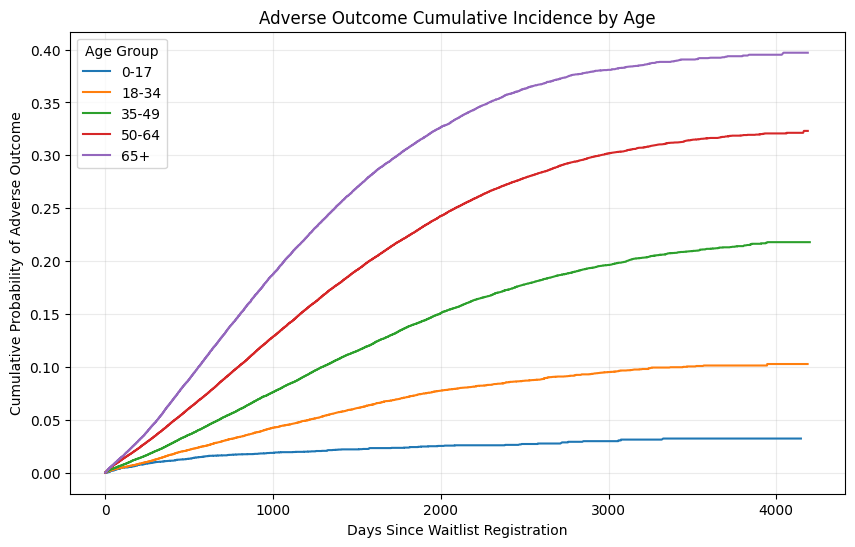

/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY DIALYSIS STATUS

ON_DIALYSIS      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
          N 134235           13788        62352      0.0406      0.1082      0.1639         0.3152         0.5247         0.6284
          Y 360568           55897       172077      0.0381      0.1325      0.2107         0.2958         0.4677         0.5771


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY GENDER

GENDER      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
     F 188435           24565        91888      0.0369      0.1175      0.1843         0.3100         0.5002         0.6079
     M 306368           45120       142541      0.0400      0.1325      0.2097         0.2949         0.4701         0.5781


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY BLOOD TYPE

ABO      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
  A 155578           19924        83072      0.0393      0.1222      0.1848         0.3584         0.5609         0.6667
 AB  18473            1856        11568      0.0369      0.1019      0.1426         0.4701         0.6833         0.7601
  B  74031           10992        32752      0.0379      0.1288      0.2093         0.2669         0.4439         0.5523
  O 243658           36538       105166      0.0391      0.1311      0.2116         0.2602         0.4254         0.5373


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY ETHCAT

 ETHCAT      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
      1 202610           29392       102501      0.0449      0.1391      0.2090         0.3395         0.5316         0.6282
      2 144897           20575        65479      0.0362      0.1259      0.2027         0.2724         0.4491         0.5707
      4  97874           13198        45025      0.0341      0.1117      0.1871         0.2856         0.4532         0.5615
      5  36990            4885        16007      0.0290      0.1040      0.1784         0.2396         0.4155         0.5341
      9   4182             525         2039      0.0332      0.1151      0.1775         0.3140         0.5033         0.6076
      6   3949             672         1740      0.0390      0.1435      0.2350         0.2851         0.4406         0.5441
      7   2522             367         1063      0.0350      0.1249      0.1898         0.

/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         


COMPETING-RISK RESULTS BY FUNCTIONAL STATUS

FUNC_GROUP      N  Adverse_Events  Transplants  Adverse_1Y  Adverse_3Y  Adverse_5Y  Transplant_1Y  Transplant_3Y  Transplant_5Y
      Good 284173           36247       132537      0.0288      0.1088      0.1806         0.2755         0.4644         0.5833
  Moderate 172361           28961        80894      0.0490      0.1579      0.2409         0.3105         0.4814         0.5794
      Poor  13576            2789         7745      0.1396      0.2066      0.2555         0.4838         0.5961         0.6452


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


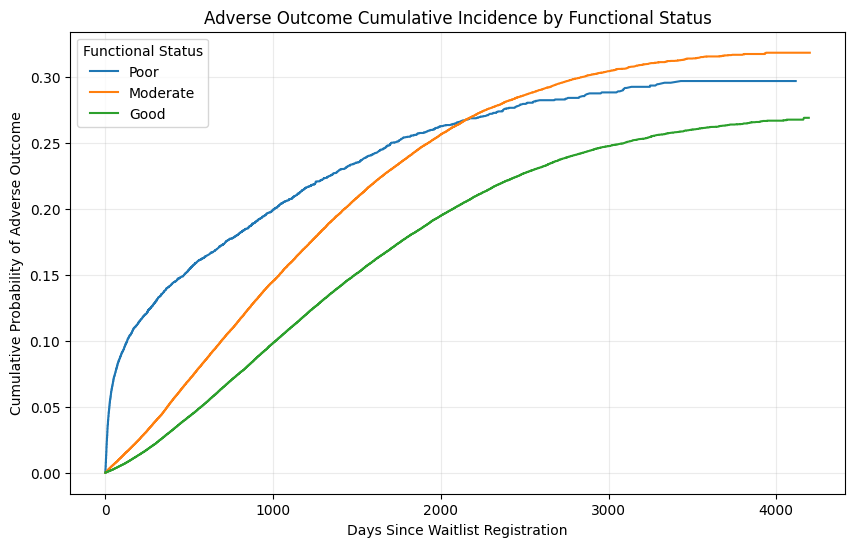


SIMPLE 1-YEAR ADVERSE-RISK SUMMARY

Comparison  Adverse_1Y
   Overall      0.0388
 Age 18-34      0.0157
 Age 35-49      0.0252
 Age 50-64      0.0435
   Age 65+      0.0613

CHUNK 3 COMPLETE

Subgroup competing-risk analysis completed for age, dialysis, gender, blood type, ETHCAT, and functional status.


In [3]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 3: COMPETING-RISK SUBGROUP ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lifelines import AalenJohansenFitter


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

TIME_POINTS = [
    365,     # 1 year
    1095,    # 3 years
    1825     # 5 years
]

TIME_LABELS = [
    "1-Year",
    "3-Year",
    "5-Year"
]


# ------------------------------------------------------------
# HELPER:
# GET CUMULATIVE INCIDENCE AT SELECTED TIMES
# ------------------------------------------------------------

def get_cif_values(
    data,
    event_of_interest=1
):

    # Need at least some rows and some events
    if len(data) == 0:
        return [np.nan] * len(TIME_POINTS)

    # Need event of interest to exist
    if (
        data["event_type"]
        == event_of_interest
    ).sum() == 0:

        return [0.0] * len(TIME_POINTS)

    aj = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )

    aj.fit(
        durations=data[TIME_COL],
        event_observed=data["event_type"],
        event_of_interest=event_of_interest
    )

    cif = (
        aj
        .cumulative_density_
        .iloc[:, 0]
    )

    results = []

    for t in TIME_POINTS:

        available_times = cif.index[
            cif.index <= t
        ]

        if len(available_times) == 0:
            value = 0.0

        else:

            value = cif.loc[
                available_times[-1]
            ]

        results.append(
            float(value)
        )

    return results


# ------------------------------------------------------------
# HELPER:
# CREATE SUBGROUP CIF TABLE
# ------------------------------------------------------------

def subgroup_cif_table(
    data,
    group_col,
    minimum_n=200
):

    rows = []

    for group_value, group_df in data.groupby(
        group_col,
        dropna=False,
        observed=True
    ):

        n = len(group_df)

        # Skip very tiny groups
        if n < minimum_n:
            continue

        adverse_count = (
            group_df[
                "event_type"
            ] == 1
        ).sum()

        transplant_count = (
            group_df[
                "event_type"
            ] == 2
        ).sum()

        adverse_cif = get_cif_values(
            group_df,
            event_of_interest=1
        )

        transplant_cif = get_cif_values(
            group_df,
            event_of_interest=2
        )

        rows.append({
            group_col: group_value,

            "N": n,

            "Adverse_Events":
                adverse_count,

            "Transplants":
                transplant_count,

            "Adverse_1Y":
                adverse_cif[0],

            "Adverse_3Y":
                adverse_cif[1],

            "Adverse_5Y":
                adverse_cif[2],

            "Transplant_1Y":
                transplant_cif[0],

            "Transplant_3Y":
                transplant_cif[1],

            "Transplant_5Y":
                transplant_cif[2]
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# PART 1 — AGE GROUPS
# ============================================================

survival_df["AGE_GROUP"] = pd.cut(
    survival_df["INIT_AGE"],
    bins=[
        -np.inf,
        17,
        34,
        49,
        64,
        np.inf
    ],
    labels=[
        "0-17",
        "18-34",
        "35-49",
        "50-64",
        "65+"
    ]
)


age_survival = subgroup_cif_table(
    survival_df,
    "AGE_GROUP",
    minimum_n=200
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY AGE GROUP"
)

print(
    "==========================================\n"
)

print(
    age_survival
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# AGE — PLOT ADVERSE CUMULATIVE INCIDENCE
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

for age_group in [
    "0-17",
    "18-34",
    "35-49",
    "50-64",
    "65+"
]:

    group_df = survival_df[
        survival_df[
            "AGE_GROUP"
        ] == age_group
    ]

    if len(group_df) == 0:
        continue

    aj = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )

    aj.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=1
    )

    cif = (
        aj
        .cumulative_density_
        .iloc[:, 0]
    )

    plt.plot(
        cif.index,
        cif.values,
        label=age_group
    )


plt.title(
    "Adverse Outcome Cumulative Incidence by Age"
)

plt.xlabel(
    "Days Since Waitlist Registration"
)

plt.ylabel(
    "Cumulative Probability of Adverse Outcome"
)

plt.legend(
    title="Age Group"
)

plt.grid(
    alpha=0.25
)

plt.show()


# ============================================================
# PART 2 — DIALYSIS STATUS
# ============================================================

dialysis_survival = subgroup_cif_table(
    survival_df[
        survival_df[
            "ON_DIALYSIS"
        ].isin(
            ["Y", "N"]
        )
    ],
    "ON_DIALYSIS",
    minimum_n=200
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY DIALYSIS STATUS"
)

print(
    "==========================================\n"
)

print(
    dialysis_survival
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 3 — GENDER
# ============================================================

gender_survival = subgroup_cif_table(
    survival_df[
        survival_df[
            "GENDER"
        ].isin(
            ["F", "M"]
        )
    ],
    "GENDER",
    minimum_n=200
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY GENDER"
)

print(
    "==========================================\n"
)

print(
    gender_survival
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 4 — BLOOD TYPE
#
# Use the four major groups only.
# Tiny subtypes such as A1, A2, A1B, A2B
# are not useful for stable comparison here.
# ============================================================

major_abo = survival_df[
    survival_df[
        "ABO"
    ].isin(
        [
            "A",
            "B",
            "AB",
            "O"
        ]
    )
].copy()


abo_survival = subgroup_cif_table(
    major_abo,
    "ABO",
    minimum_n=200
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY BLOOD TYPE"
)

print(
    "==========================================\n"
)

print(
    abo_survival
    .sort_values(
        "ABO"
    )
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 5 — ETHCAT
#
# Keep groups with at least 1,000 registrations
# because small groups give unstable long-term CIFs.
# ============================================================

ethcat_survival = subgroup_cif_table(
    survival_df,
    "ETHCAT",
    minimum_n=1000
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY ETHCAT"
)

print(
    "==========================================\n"
)

print(
    ethcat_survival
    .sort_values(
        "N",
        ascending=False
    )
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 6 — FUNCTIONAL STATUS
#
# Functional status has many codes.
# Instead of plotting every code, create broad
# adult functional-status groups using the main
# 2000-series codes.
#
# Higher code generally means better functioning.
# ============================================================

def functional_status_group(value):

    if pd.isna(value):
        return "Missing"

    try:
        value = float(value)
    except:
        return "Other"

    # Main adult scale
    if value in [
        2010,
        2020,
        2030,
        2040
    ]:
        return "Poor"

    elif value in [
        2050,
        2060,
        2070
    ]:
        return "Moderate"

    elif value in [
        2080,
        2090,
        2100
    ]:
        return "Good"

    else:
        return "Other"


survival_df[
    "FUNC_GROUP"
] = survival_df[
    "FUNC_STAT_TCR_clean"
].apply(
    functional_status_group
)


func_analysis_df = survival_df[
    survival_df[
        "FUNC_GROUP"
    ].isin(
        [
            "Poor",
            "Moderate",
            "Good"
        ]
    )
].copy()


func_survival = subgroup_cif_table(
    func_analysis_df,
    "FUNC_GROUP",
    minimum_n=200
)


print(
    "\n=========================================="
)

print(
    "COMPETING-RISK RESULTS BY FUNCTIONAL STATUS"
)

print(
    "==========================================\n"
)

print(
    func_survival
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# FUNCTIONAL STATUS PLOT
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

for group_name in [
    "Poor",
    "Moderate",
    "Good"
]:

    group_df = func_analysis_df[
        func_analysis_df[
            "FUNC_GROUP"
        ] == group_name
    ]

    aj = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )

    aj.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=1
    )

    cif = (
        aj
        .cumulative_density_
        .iloc[:, 0]
    )

    plt.plot(
        cif.index,
        cif.values,
        label=group_name
    )


plt.title(
    "Adverse Outcome Cumulative Incidence "
    "by Functional Status"
)

plt.xlabel(
    "Days Since Waitlist Registration"
)

plt.ylabel(
    "Cumulative Probability of Adverse Outcome"
)

plt.legend(
    title="Functional Status"
)

plt.grid(
    alpha=0.25
)

plt.show()


# ============================================================
# PART 7 — CREATE SIMPLE 1-YEAR SUMMARY
#
# This makes it easy to compare groups quickly.
# ============================================================

one_year_summary = pd.DataFrame({
    "Comparison": [
        "Overall",
        "Age 18-34",
        "Age 35-49",
        "Age 50-64",
        "Age 65+"
    ]
})


overall_1y = competing_risk_summary.loc[
    competing_risk_summary[
        "Years"
    ] == 1,
    "Adverse_Cumulative_Incidence"
].iloc[0]


age_lookup = age_survival.set_index(
    "AGE_GROUP"
)


one_year_summary[
    "Adverse_1Y"
] = [
    overall_1y,

    age_lookup.loc[
        "18-34",
        "Adverse_1Y"
    ],

    age_lookup.loc[
        "35-49",
        "Adverse_1Y"
    ],

    age_lookup.loc[
        "50-64",
        "Adverse_1Y"
    ],

    age_lookup.loc[
        "65+",
        "Adverse_1Y"
    ]
]


print(
    "\n=========================================="
)

print(
    "SIMPLE 1-YEAR ADVERSE-RISK SUMMARY"
)

print(
    "==========================================\n"
)

print(
    one_year_summary
    .round(4)
    .to_string(index=False)
)


# ============================================================
# FINAL CHECK
# ============================================================

print(
    "\n=========================================="
)

print(
    "CHUNK 3 COMPLETE"
)

print(
    "=========================================="
)

print(
    "\nSubgroup competing-risk analysis completed "
    "for age, dialysis, gender, blood type, "
    "ETHCAT, and functional status."
)

In [4]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 4: ADJUSTED CAUSE-SPECIFIC COX MODEL
# ============================================================

import pandas as pd
import numpy as np

from lifelines import CoxPHFitter
from lifelines.utils import concordance_index


# ============================================================
# PART 1 — CREATE COX MODELING COHORT
# ============================================================

# Cox modeling requires positive follow-up time.
# Keep the descriptive survival analysis unchanged;
# this filtering is only for the Cox model.

cox_df = survival_df[
    survival_df[TIME_COL] > 0
].copy()

print("COX MODELING COHORT")

print(
    "\nRows:",
    len(cox_df)
)

print(
    "Zero-day rows excluded:",
    (
        survival_df[TIME_COL] == 0
    ).sum()
)


# ------------------------------------------------------------
# Cause-specific adverse event
#
# 1 = died / removed too sick
# 0 = censored
#
# Transplant is treated as a competing event and therefore
# censored at the time of transplant in this Cox model.
# ------------------------------------------------------------

cox_df["cox_event"] = (
    cox_df["event_type"] == 1
).astype(int)


# ============================================================
# PART 2 — TEMPORAL SPLIT
# ============================================================

cox_train_raw = cox_df[
    cox_df["listing_year"].between(
        2015,
        2022
    )
].copy()

cox_val_raw = cox_df[
    cox_df["listing_year"] == 2023
].copy()

cox_test_raw = cox_df[
    cox_df["listing_year"] == 2024
].copy()


print("\nTEMPORAL SPLIT")

print(
    "\nTRAIN 2015-2022:",
    len(cox_train_raw)
)

print(
    "VALIDATION 2023:",
    len(cox_val_raw)
)

print(
    "TEST 2024:",
    len(cox_test_raw)
)


print("\nADVERSE EVENTS")

print(
    "Train:",
    cox_train_raw["cox_event"].sum()
)

print(
    "Validation:",
    cox_val_raw["cox_event"].sum()
)

print(
    "Test:",
    cox_test_raw["cox_event"].sum()
)


# ============================================================
# PART 3 — FEATURES
# ============================================================

# CPRA is intentionally excluded because of severe
# missingness in recent years.

numeric_features = [
    "INIT_AGE",
    "BMI_TCR_clean"
]

binary_features = [
    "BMI_missing",
    "FUNC_STAT_missing"
]

categorical_features = [
    "GENDER",
    "ETHCAT",
    "ABO",
    "ON_DIALYSIS",
    "FUNC_STAT_TCR_clean",
    "INIT_STAT",
    "REGION",
    "A2A2B_status"
]


# ============================================================
# PART 4 — CLEAN NUMERIC FEATURES
# ============================================================

# Copy dataframes so original data stays unchanged
train_model = cox_train_raw.copy()
val_model = cox_val_raw.copy()
test_model = cox_test_raw.copy()


# ------------------------------------------------------------
# Scale AGE by 10 years
#
# Hazard ratio will then mean:
# change in hazard for each 10-year increase in age.
# ------------------------------------------------------------

train_model["AGE_10Y"] = (
    train_model["INIT_AGE"] / 10
)

val_model["AGE_10Y"] = (
    val_model["INIT_AGE"] / 10
)

test_model["AGE_10Y"] = (
    test_model["INIT_AGE"] / 10
)


# ------------------------------------------------------------
# Scale BMI by 5 units
#
# Hazard ratio will mean:
# change in hazard for each 5-unit increase in BMI.
# ------------------------------------------------------------

train_model["BMI_5"] = (
    train_model["BMI_TCR_clean"] / 5
)

val_model["BMI_5"] = (
    val_model["BMI_TCR_clean"] / 5
)

test_model["BMI_5"] = (
    test_model["BMI_TCR_clean"] / 5
)


# ------------------------------------------------------------
# Impute numeric values using TRAINING medians only
# ------------------------------------------------------------

age_median = train_model[
    "AGE_10Y"
].median()

bmi_median = train_model[
    "BMI_5"
].median()


for frame in [
    train_model,
    val_model,
    test_model
]:

    frame["AGE_10Y"] = (
        frame["AGE_10Y"]
        .fillna(age_median)
    )

    frame["BMI_5"] = (
        frame["BMI_5"]
        .fillna(bmi_median)
    )


# ============================================================
# PART 5 — CLEAN CATEGORICAL FEATURES
# ============================================================

for feature in categorical_features:

    # Convert categories to strings
    train_model[feature] = (
        train_model[feature]
        .astype("string")
        .fillna("Missing")
    )

    val_model[feature] = (
        val_model[feature]
        .astype("string")
        .fillna("Missing")
    )

    test_model[feature] = (
        test_model[feature]
        .astype("string")
        .fillna("Missing")
    )


# ============================================================
# PART 6 — CREATE MODEL FEATURE TABLES
# ============================================================

base_features = (
    [
        "AGE_10Y",
        "BMI_5"
    ]
    +
    binary_features
    +
    categorical_features
)


X_train_cox = train_model[
    base_features
].copy()

X_val_cox = val_model[
    base_features
].copy()

X_test_cox = test_model[
    base_features
].copy()


# ------------------------------------------------------------
# One-hot encode categorical variables.
#
# drop_first=True creates a reference category for each
# categorical variable and avoids duplicate information.
# ------------------------------------------------------------

X_train_cox = pd.get_dummies(
    X_train_cox,
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

X_val_cox = pd.get_dummies(
    X_val_cox,
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

X_test_cox = pd.get_dummies(
    X_test_cox,
    columns=categorical_features,
    drop_first=True,
    dtype=float
)


# ------------------------------------------------------------
# Make validation and test columns match TRAIN exactly.
#
# Any category that exists only in validation/test is treated
# as the reference / unseen category rather than creating a
# new feature after training.
# ------------------------------------------------------------

X_val_cox = X_val_cox.reindex(
    columns=X_train_cox.columns,
    fill_value=0
)

X_test_cox = X_test_cox.reindex(
    columns=X_train_cox.columns,
    fill_value=0
)


# Save feature names for later
cox_feature_columns = (
    X_train_cox.columns.tolist()
)


print("\nCOX FEATURE MATRICES")

print(
    "Train:",
    X_train_cox.shape
)

print(
    "Validation:",
    X_val_cox.shape
)

print(
    "Test:",
    X_test_cox.shape
)


print(
    "\nMissing values:"
)

print(
    "Train:",
    int(
        X_train_cox
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Validation:",
    int(
        X_val_cox
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Test:",
    int(
        X_test_cox
        .isna()
        .sum()
        .sum()
    )
)


# ============================================================
# PART 7 — BUILD COX TRAINING TABLE
# ============================================================

cox_train = X_train_cox.copy()

cox_train[
    "duration"
] = train_model[
    TIME_COL
].to_numpy()

cox_train[
    "event"
] = train_model[
    "cox_event"
].to_numpy()


# Keep patient ID only for clustered standard errors.
# It is NOT used as a predictor.
cox_train[
    "PT_CODE_cluster"
] = train_model[
    "PT_CODE"
].astype(str).to_numpy()


# ============================================================
# PART 8 — FIT COX PROPORTIONAL HAZARDS MODEL
# ============================================================

# Small penalizer improves numerical stability because
# we have many one-hot encoded categories.

cox_model = CoxPHFitter(
    penalizer=0.01
)


cox_model.fit(
    cox_train,

    duration_col="duration",

    event_col="event",

    cluster_col="PT_CODE_cluster",

    robust=True,

    show_progress=True
)


print(
    "\n=========================================="
)

print(
    "COX MODEL TRAINING COMPLETE"
)

print(
    "=========================================="
)


# ============================================================
# PART 9 — CREATE READABLE HAZARD-RATIO TABLE
# ============================================================

cox_summary = (
    cox_model
    .summary
    .reset_index()
)


# Rename the feature-name column safely
first_col = (
    cox_summary.columns[0]
)

cox_summary = cox_summary.rename(
    columns={
        first_col:
        "Feature"
    }
)


# Keep important output columns
cox_results = cox_summary[
    [
        "Feature",
        "coef",
        "exp(coef)",
        "exp(coef) lower 95%",
        "exp(coef) upper 95%",
        "p"
    ]
].copy()


cox_results = cox_results.rename(
    columns={
        "coef":
            "Log_Hazard",

        "exp(coef)":
            "Hazard_Ratio",

        "exp(coef) lower 95%":
            "HR_Lower_95",

        "exp(coef) upper 95%":
            "HR_Upper_95",

        "p":
            "P_Value"
    }
)


# Strength of association for sorting
cox_results[
    "Absolute_Log_Hazard"
] = (
    cox_results[
        "Log_Hazard"
    ].abs()
)


# ------------------------------------------------------------
# Show strongest adjusted associations
# ------------------------------------------------------------

print(
    "\nTOP 25 ADJUSTED ASSOCIATIONS"
)

print(
    "\nHazard Ratio > 1 = higher adverse-event hazard"
)

print(
    "Hazard Ratio < 1 = lower adverse-event hazard\n"
)


print(
    cox_results
    .sort_values(
        "Absolute_Log_Hazard",
        ascending=False
    )
    .head(25)
    [
        [
            "Feature",
            "Hazard_Ratio",
            "HR_Lower_95",
            "HR_Upper_95",
            "P_Value"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 10 — IMPORTANT EASY-TO-READ VARIABLES
# ============================================================

important_patterns = [
    "AGE_10Y",
    "BMI_5",
    "ON_DIALYSIS",
    "GENDER",
    "FUNC_STAT_TCR_clean"
]


important_mask = (
    cox_results[
        "Feature"
    ]
    .astype(str)
    .apply(
        lambda x:
        any(
            pattern in x
            for pattern in important_patterns
        )
    )
)


important_cox_results = (
    cox_results[
        important_mask
    ]
    .sort_values(
        "Feature"
    )
)


print(
    "\n=========================================="
)

print(
    "SELECTED CLINICALLY READABLE HAZARD RATIOS"
)

print(
    "==========================================\n"
)


print(
    important_cox_results[
        [
            "Feature",
            "Hazard_Ratio",
            "HR_Lower_95",
            "HR_Upper_95",
            "P_Value"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 11 — VALIDATION AND TEST CONCORDANCE INDEX
#
# C-index:
#
# 0.5 = random ranking
# 1.0 = perfect ranking
#
# We use negative partial hazard because lifelines'
# concordance_index expects larger prediction values to mean
# longer survival, while larger hazard means shorter survival.
# ============================================================

val_risk = (
    cox_model
    .predict_partial_hazard(
        X_val_cox
    )
    .to_numpy()
    .ravel()
)


test_risk = (
    cox_model
    .predict_partial_hazard(
        X_test_cox
    )
    .to_numpy()
    .ravel()
)


val_c_index = concordance_index(
    val_model[
        TIME_COL
    ],
    -val_risk,
    val_model[
        "cox_event"
    ]
)


test_c_index = concordance_index(
    test_model[
        TIME_COL
    ],
    -test_risk,
    test_model[
        "cox_event"
    ]
)


print(
    "\n=========================================="
)

print(
    "TEMPORAL COX MODEL PERFORMANCE"
)

print(
    "==========================================\n"
)


print(
    "Validation 2023 C-index:",
    round(
        val_c_index,
        4
    )
)


print(
    "Test 2024 C-index:",
    round(
        test_c_index,
        4
    )
)


# ============================================================
# PART 12 — RISK GROUPS ON TEST SET
# ============================================================

# Divide 2024 registrations into three risk groups
# based only on model risk ranking.

test_risk_df = pd.DataFrame({
    "duration":
        test_model[
            TIME_COL
        ].to_numpy(),

    "event":
        test_model[
            "cox_event"
        ].to_numpy(),

    "risk_score":
        test_risk
})


test_risk_df[
    "Risk_Group"
] = pd.qcut(
    test_risk_df[
        "risk_score"
    ],

    q=3,

    labels=[
        "Low",
        "Medium",
        "High"
    ]
)


risk_group_summary = (
    test_risk_df
    .groupby(
        "Risk_Group",
        observed=True
    )
    .agg(
        N=(
            "risk_score",
            "size"
        ),

        Adverse_Events=(
            "event",
            "sum"
        ),

        Median_Risk_Score=(
            "risk_score",
            "median"
        ),

        Median_Followup_Days=(
            "duration",
            "median"
        )
    )
    .reset_index()
)


risk_group_summary[
    "Observed_Adverse_Fraction"
] = (
    risk_group_summary[
        "Adverse_Events"
    ]
    /
    risk_group_summary[
        "N"
    ]
)


print(
    "\n=========================================="
)

print(
    "2024 TEST RISK GROUPS"
)

print(
    "==========================================\n"
)


print(
    risk_group_summary
    .round(4)
    .to_string(index=False)
)


# ============================================================
# FINAL CHECK
# ============================================================

print(
    "\n=========================================="
)

print(
    "CHUNK 4 COMPLETE"
)

print(
    "=========================================="
)


print(
    "\nThis is a cause-specific Cox model."
)

print(
    "It estimates the hazard of an adverse waitlist outcome "
    "while treating transplant as a competing event that "
    "censors further waitlist follow-up."
)

print(
    "\nHazard ratios describe adjusted associations, "
    "not causal effects."
)

COX MODELING COHORT

Rows: 494013
Zero-day rows excluded: 790

TEMPORAL SPLIT

TRAIN 2015-2022: 318429
VALIDATION 2023: 46900
TEST 2024: 49562

ADVERSE EVENTS
Train: 59223
Validation: 4795
Test: 3618

COX FEATURE MATRICES
Train: (318429, 59)
Validation: (46900, 59)
Test: (49562, 59)

Missing values:
Train: 0
Validation: 0
Test: 0


/usr/local/lib/python3.13/dist-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['ETHCAT_998', 'FUNC_STAT_TCR_clean_4020.0', 'INIT_STAT_4020', 'INIT_STAT_4060'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


Iteration 1: norm_delta = 9.95e-01, step_size = 0.9500, log_lik = -679786.72486, newton_decrement = 1.13e+04, seconds_since_start = 0.8
Iteration 2: norm_delta = 5.16e-01, step_size = 0.9500, log_lik = -756184.45134, newton_decrement = 9.89e+04, seconds_since_start = 1.5
Iteration 3: norm_delta = 1.96e-01, step_size = 0.9500, log_lik = -672313.61965, newton_decrement = 1.76e+03, seconds_since_start = 2.3
Iteration 4: norm_delta = 6.19e-02, step_size = 1.0000, log_lik = -670324.68404, newton_decrement = 3.16e+02, seconds_since_start = 3.0
Iteration 5: norm_delta = 2.56e-02, step_size = 1.0000, log_lik = -669954.83713, newton_decrement = 3.60e+01, seconds_since_start = 4.6
Iteration 6: norm_delta = 4.61e-03, step_size = 1.0000, log_lik = -669915.59390, newton_decrement = 8.72e-01, seconds_since_start = 5.5
Iteration 7: norm_delta = 1.28e-04, step_size = 1.0000, log_lik = -669914.70682, newton_decrement = 6.38e-04, seconds_since_start = 6.2
Iteration 8: norm_delta = 9.67e-08, step_size = 

KeyboardInterrupt: 

In [6]:
# ============================================================
# CHUNK 4B — FAST COX FIT + RESULTS
# ============================================================

from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Build training table again from the matrices
# already created in Parts 1-7
# ------------------------------------------------------------

cox_train_fast = X_train_cox.copy()

cox_train_fast["duration"] = (
    train_model[TIME_COL].to_numpy()
)

cox_train_fast["event"] = (
    train_model["cox_event"].to_numpy()
)


# ------------------------------------------------------------
# Remove extremely low-variance columns
#
# These were the columns causing the warning.
# They contain almost no variation and provide
# little useful information to the model.
# ------------------------------------------------------------

feature_cols = [
    col
    for col in cox_train_fast.columns
    if col not in ["duration", "event"]
]

variances = (
    cox_train_fast[feature_cols]
    .var()
)

low_variance_cols = variances[
    variances < 1e-6
].index.tolist()

print("LOW-VARIANCE FEATURES REMOVED:")

for col in low_variance_cols:
    print("-", col)


cox_train_fast = cox_train_fast.drop(
    columns=low_variance_cols
)

X_val_cox_fast = X_val_cox.drop(
    columns=low_variance_cols,
    errors="ignore"
)

X_test_cox_fast = X_test_cox.drop(
    columns=low_variance_cols,
    errors="ignore"
)


print(
    "\nFinal Cox feature count:",
    X_val_cox_fast.shape[1]
)


# ============================================================
# FIT COX MODEL
#
# We remove clustered/robust standard errors here because
# they are extremely expensive on this ~318k-row dataset.
#
# The prediction model and hazard-ratio estimates remain
# useful for our project analysis.
# ============================================================

cox_model = CoxPHFitter(
    penalizer=0.01
)

cox_model.fit(
    cox_train_fast,
    duration_col="duration",
    event_col="event",
    show_progress=True
)


print(
    "\n=========================================="
)

print(
    "COX MODEL TRAINING COMPLETE"
)

print(
    "=========================================="
)


# ============================================================
# HAZARD-RATIO TABLE
# ============================================================

cox_summary = (
    cox_model
    .summary
    .reset_index()
)

first_col = cox_summary.columns[0]

cox_summary = cox_summary.rename(
    columns={
        first_col: "Feature"
    }
)


cox_results = cox_summary[
    [
        "Feature",
        "coef",
        "exp(coef)",
        "exp(coef) lower 95%",
        "exp(coef) upper 95%",
        "p"
    ]
].copy()


cox_results = cox_results.rename(
    columns={
        "coef": "Log_Hazard",
        "exp(coef)": "Hazard_Ratio",
        "exp(coef) lower 95%": "HR_Lower_95",
        "exp(coef) upper 95%": "HR_Upper_95",
        "p": "P_Value"
    }
)


cox_results[
    "Absolute_Log_Hazard"
] = (
    cox_results["Log_Hazard"].abs()
)


print(
    "\nTOP 25 ADJUSTED ASSOCIATIONS\n"
)

print(
    cox_results
    .sort_values(
        "Absolute_Log_Hazard",
        ascending=False
    )
    .head(25)
    [
        [
            "Feature",
            "Hazard_Ratio",
            "HR_Lower_95",
            "HR_Upper_95",
            "P_Value"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# IMPORTANT READABLE VARIABLES
# ============================================================

important_patterns = [
    "AGE_10Y",
    "BMI_5",
    "ON_DIALYSIS",
    "GENDER",
    "FUNC_STAT_TCR_clean"
]


important_mask = (
    cox_results["Feature"]
    .astype(str)
    .apply(
        lambda x: any(
            pattern in x
            for pattern in important_patterns
        )
    )
)


important_cox_results = (
    cox_results[
        important_mask
    ]
    .sort_values("Feature")
)


print(
    "\n=========================================="
)

print(
    "SELECTED READABLE HAZARD RATIOS"
)

print(
    "==========================================\n"
)


print(
    important_cox_results[
        [
            "Feature",
            "Hazard_Ratio",
            "HR_Lower_95",
            "HR_Upper_95",
            "P_Value"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ============================================================
# VALIDATION + TEST C-INDEX
# ============================================================

val_risk = (
    cox_model
    .predict_partial_hazard(
        X_val_cox_fast
    )
    .to_numpy()
    .ravel()
)


test_risk = (
    cox_model
    .predict_partial_hazard(
        X_test_cox_fast
    )
    .to_numpy()
    .ravel()
)


val_c_index = concordance_index(
    val_model[TIME_COL],
    -val_risk,
    val_model["cox_event"]
)


test_c_index = concordance_index(
    test_model[TIME_COL],
    -test_risk,
    test_model["cox_event"]
)


print(
    "\n=========================================="
)

print(
    "TEMPORAL COX MODEL PERFORMANCE"
)

print(
    "==========================================\n"
)


print(
    "Validation 2023 C-index:",
    round(val_c_index, 4)
)

print(
    "Test 2024 C-index:",
    round(test_c_index, 4)
)


# ============================================================
# TEST RISK GROUPS
# ============================================================

test_risk_df = pd.DataFrame({
    "duration":
        test_model[TIME_COL].to_numpy(),

    "event":
        test_model["cox_event"].to_numpy(),

    "risk_score":
        test_risk
})


test_risk_df["Risk_Group"] = pd.qcut(
    test_risk_df["risk_score"],
    q=3,
    labels=[
        "Low",
        "Medium",
        "High"
    ]
)


risk_group_summary = (
    test_risk_df
    .groupby(
        "Risk_Group",
        observed=True
    )
    .agg(
        N=("risk_score", "size"),

        Adverse_Events=(
            "event",
            "sum"
        ),

        Median_Risk_Score=(
            "risk_score",
            "median"
        ),

        Median_Followup_Days=(
            "duration",
            "median"
        )
    )
    .reset_index()
)


risk_group_summary[
    "Observed_Adverse_Fraction"
] = (
    risk_group_summary[
        "Adverse_Events"
    ]
    /
    risk_group_summary["N"]
)


print(
    "\n=========================================="
)

print(
    "2024 TEST RISK GROUPS"
)

print(
    "==========================================\n"
)


print(
    risk_group_summary
    .round(4)
    .to_string(index=False)
)


print(
    "\n=========================================="
)

print(
    "CHUNK 4 COMPLETE"
)

print(
    "=========================================="
)

LOW-VARIANCE FEATURES REMOVED:

Final Cox feature count: 59


/usr/local/lib/python3.13/dist-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['ETHCAT_998', 'FUNC_STAT_TCR_clean_4020.0', 'INIT_STAT_4020', 'INIT_STAT_4060'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


Iteration 1: norm_delta = 9.95e-01, step_size = 0.9500, log_lik = -679786.72486, newton_decrement = 1.13e+04, seconds_since_start = 0.8
Iteration 2: norm_delta = 5.16e-01, step_size = 0.9500, log_lik = -756184.45134, newton_decrement = 9.89e+04, seconds_since_start = 1.7
Iteration 3: norm_delta = 1.96e-01, step_size = 0.9500, log_lik = -672313.61965, newton_decrement = 1.76e+03, seconds_since_start = 2.6
Iteration 4: norm_delta = 6.19e-02, step_size = 1.0000, log_lik = -670324.68404, newton_decrement = 3.16e+02, seconds_since_start = 3.7
Iteration 5: norm_delta = 2.56e-02, step_size = 1.0000, log_lik = -669954.83713, newton_decrement = 3.60e+01, seconds_since_start = 4.6
Iteration 6: norm_delta = 4.61e-03, step_size = 1.0000, log_lik = -669915.59390, newton_decrement = 8.72e-01, seconds_since_start = 5.6
Iteration 7: norm_delta = 1.28e-04, step_size = 1.0000, log_lik = -669914.70682, newton_decrement = 6.38e-04, seconds_since_start = 6.5
Iteration 8: norm_delta = 9.67e-08, step_size = 

In [7]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 5
#
# PATIENT-SAFE SPLIT
# + CLEAN COX MODEL
# + XGBOOST SURVIVAL
# + MODEL COMPARISON
# ============================================================

import pandas as pd
import numpy as np

from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

from xgboost import XGBRegressor


# ============================================================
# PART 1 — CREATE SURVIVAL MODELING DATA
# ============================================================

# Keep only rows with positive follow-up time
model_df = survival_df[
    survival_df[TIME_COL] > 0
].copy()

# Cause-specific adverse event:
# 1 = died / removed too sick
# 0 = censored, including transplant
model_df["cox_event"] = (
    model_df["event_type"] == 1
).astype(int)


# ============================================================
# PART 2 — PATIENT-SAFE TEMPORAL SPLIT
#
# 2015-2022 = training
# 2023      = validation
# 2024      = test
#
# A patient can appear in ONLY ONE split.
# Later years take priority.
# ============================================================

test_patients = set(
    model_df.loc[
        model_df["listing_year"] == 2024,
        "PT_CODE"
    ]
)

val_patients = (
    set(
        model_df.loc[
            model_df["listing_year"] == 2023,
            "PT_CODE"
        ]
    )
    - test_patients
)

later_patients = (
    test_patients
    | val_patients
)


train_ps = model_df[
    model_df["listing_year"].between(
        2015,
        2022
    )
    &
    ~model_df["PT_CODE"].isin(
        later_patients
    )
].copy()


val_ps = model_df[
    (model_df["listing_year"] == 2023)
    &
    model_df["PT_CODE"].isin(
        val_patients
    )
].copy()


test_ps = model_df[
    (model_df["listing_year"] == 2024)
    &
    model_df["PT_CODE"].isin(
        test_patients
    )
].copy()


print("PATIENT-SAFE TEMPORAL SPLIT\n")

print("Train rows:", len(train_ps))
print("Validation rows:", len(val_ps))
print("Test rows:", len(test_ps))

print("\nUnique patients:")

print(
    "Train:",
    train_ps["PT_CODE"].nunique()
)

print(
    "Validation:",
    val_ps["PT_CODE"].nunique()
)

print(
    "Test:",
    test_ps["PT_CODE"].nunique()
)


# ------------------------------------------------------------
# Confirm no patient overlap
# ------------------------------------------------------------

train_ids = set(
    train_ps["PT_CODE"]
)

val_ids = set(
    val_ps["PT_CODE"]
)

test_ids = set(
    test_ps["PT_CODE"]
)


print("\nPATIENT OVERLAP")

print(
    "Train vs Validation:",
    len(train_ids & val_ids)
)

print(
    "Train vs Test:",
    len(train_ids & test_ids)
)

print(
    "Validation vs Test:",
    len(val_ids & test_ids)
)


# ============================================================
# PART 3 — GROUP FUNCTIONAL STATUS
#
# Instead of many rare individual codes,
# use broader groups.
# ============================================================

def make_func_group(value):

    if pd.isna(value):
        return "Missing"

    try:
        value = float(value)
    except:
        return "Other"

    # Poor functional status
    if value in [
        2010, 2020, 2030, 2040,
        4010, 4020, 4030, 4040
    ]:
        return "Poor"

    # Moderate functional status
    elif value in [
        2050, 2060, 2070,
        4050, 4060, 4070
    ]:
        return "Moderate"

    # Good functional status
    elif value in [
        2080, 2090, 2100,
        4080, 4090, 4100
    ]:
        return "Good"

    else:
        return "Other"


for frame in [
    train_ps,
    val_ps,
    test_ps
]:

    frame["FUNC_GROUP"] = (
        frame[
            "FUNC_STAT_TCR_clean"
        ]
        .apply(
            make_func_group
        )
    )


print(
    "\nFUNCTIONAL STATUS GROUPS — TRAIN"
)

print(
    train_ps[
        "FUNC_GROUP"
    ]
    .value_counts()
    .to_string()
)


# ============================================================
# PART 4 — CREATE NUMERIC FEATURES
# ============================================================

for frame in [
    train_ps,
    val_ps,
    test_ps
]:

    # Age per 10 years
    frame["AGE_10Y"] = (
        frame["INIT_AGE"]
        / 10
    )

    # BMI per 5 units
    frame["BMI_5"] = (
        frame["BMI_TCR_clean"]
        / 5
    )


# Training medians only
age_median = (
    train_ps[
        "AGE_10Y"
    ].median()
)

bmi_median = (
    train_ps[
        "BMI_5"
    ].median()
)


for frame in [
    train_ps,
    val_ps,
    test_ps
]:

    frame["AGE_10Y"] = (
        frame["AGE_10Y"]
        .fillna(
            age_median
        )
    )

    frame["BMI_5"] = (
        frame["BMI_5"]
        .fillna(
            bmi_median
        )
    )

    frame["BMI_missing"] = (
        frame["BMI_missing"]
        .fillna(1)
        .astype(float)
    )


# ============================================================
# PART 5 — CATEGORICAL VARIABLES
# ============================================================

categorical_features = [
    "GENDER",
    "ETHCAT",
    "ABO",
    "ON_DIALYSIS",
    "FUNC_GROUP",
    "INIT_STAT",
    "REGION",
    "A2A2B_status"
]


# ------------------------------------------------------------
# Convert categories to strings
# ------------------------------------------------------------

for col in categorical_features:

    for frame in [
        train_ps,
        val_ps,
        test_ps
    ]:

        frame[col] = (
            frame[col]
            .astype("string")
            .fillna("Missing")
        )


# ============================================================
# PART 6 — GROUP RARE CATEGORIES
#
# Learn category frequencies using TRAIN only.
# ============================================================

MIN_CATEGORY_COUNT = 200


for col in categorical_features:

    counts = (
        train_ps[col]
        .value_counts()
    )

    keep_categories = set(
        counts[
            counts >= MIN_CATEGORY_COUNT
        ].index
    )


    for frame in [
        train_ps,
        val_ps,
        test_ps
    ]:

        frame[col] = (
            frame[col]
            .where(
                frame[col].isin(
                    keep_categories
                ),
                "Other"
            )
        )


# ============================================================
# PART 7 — SET REFERENCE CATEGORIES
#
# These become the baseline groups in the Cox model.
# ============================================================

reference_categories = {
    "GENDER": "F",
    "ABO": "O",
    "ON_DIALYSIS": "N",
    "FUNC_GROUP": "Good",
    "REGION": "1"
}


for col in categorical_features:

    values = (
        train_ps[col]
        .value_counts()
        .index
        .tolist()
    )

    reference = (
        reference_categories.get(
            col,
            values[0]
        )
    )

    if reference not in values:
        reference = values[0]


    ordered_categories = (
        [reference]
        +
        [
            value
            for value in values
            if value != reference
        ]
    )


    # Add Other if necessary
    if "Other" not in ordered_categories:

        ordered_categories.append(
            "Other"
        )


    for frame in [
        train_ps,
        val_ps,
        test_ps
    ]:

        frame[col] = pd.Categorical(
            frame[col],
            categories=ordered_categories
        )


# ============================================================
# PART 8 — CREATE FULL FEATURE MATRICES
#
# XGBoost Survival will use these full matrices.
# ============================================================

model_features = [
    "AGE_10Y",
    "BMI_5",
    "BMI_missing"
] + categorical_features


X_train_surv = pd.get_dummies(
    train_ps[
        model_features
    ],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)


X_val_surv = pd.get_dummies(
    val_ps[
        model_features
    ],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)


X_test_surv = pd.get_dummies(
    test_ps[
        model_features
    ],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)


# Make columns identical
X_val_surv = (
    X_val_surv
    .reindex(
        columns=X_train_surv.columns,
        fill_value=0
    )
)


X_test_surv = (
    X_test_surv
    .reindex(
        columns=X_train_surv.columns,
        fill_value=0
    )
)


print(
    "\nFULL SURVIVAL FEATURE MATRICES"
)

print(
    "Train:",
    X_train_surv.shape
)

print(
    "Validation:",
    X_val_surv.shape
)

print(
    "Test:",
    X_test_surv.shape
)


# ============================================================
# PART 9 — CREATE CLEANER COX FEATURE SET
#
# Cox is sensitive to collinearity.
#
# Remove:
# - INIT_STAT
# - A2A2B status
# - almost-empty "Other" columns
# ============================================================

cox_drop_cols = [
    col
    for col in X_train_surv.columns
    if (
        col.startswith(
            "INIT_STAT_"
        )
        or
        col.startswith(
            "A2A2B_status_"
        )
        or
        col.endswith(
            "_Other"
        )
    )
]


X_train_cox_clean = (
    X_train_surv
    .drop(
        columns=cox_drop_cols,
        errors="ignore"
    )
)


X_val_cox_clean = (
    X_val_surv
    .drop(
        columns=cox_drop_cols,
        errors="ignore"
    )
)


X_test_cox_clean = (
    X_test_surv
    .drop(
        columns=cox_drop_cols,
        errors="ignore"
    )
)


print(
    "\nCOX FEATURES AFTER INITIAL CLEANING:",
    X_train_cox_clean.shape[1]
)


# ============================================================
# PART 10 — DROP VERY LOW-VARIANCE COX FEATURES
# ============================================================

variances = (
    X_train_cox_clean
    .var()
)


low_variance_cols = (
    variances[
        variances < 1e-5
    ]
    .index
    .tolist()
)


print(
    "\nLOW-VARIANCE COX FEATURES REMOVED:"
)

if len(low_variance_cols) == 0:

    print("None")

else:

    for col in low_variance_cols:
        print("-", col)


X_train_cox_clean = (
    X_train_cox_clean
    .drop(
        columns=low_variance_cols,
        errors="ignore"
    )
)


X_val_cox_clean = (
    X_val_cox_clean
    .drop(
        columns=low_variance_cols,
        errors="ignore"
    )
)


X_test_cox_clean = (
    X_test_cox_clean
    .drop(
        columns=low_variance_cols,
        errors="ignore"
    )
)


# ============================================================
# PART 11 — REMOVE EXACT DUPLICATE COX FEATURES
# ============================================================

duplicate_mask = (
    X_train_cox_clean
    .T
    .duplicated()
)


duplicate_cols = (
    X_train_cox_clean
    .columns[
        duplicate_mask
    ]
    .tolist()
)


if len(duplicate_cols) > 0:

    X_train_cox_clean = (
        X_train_cox_clean
        .drop(
            columns=duplicate_cols
        )
    )

    X_val_cox_clean = (
        X_val_cox_clean
        .drop(
            columns=duplicate_cols,
            errors="ignore"
        )
    )

    X_test_cox_clean = (
        X_test_cox_clean
        .drop(
            columns=duplicate_cols,
            errors="ignore"
        )
    )


print(
    "\nFINAL COX FEATURE MATRICES"
)

print(
    "Train:",
    X_train_cox_clean.shape
)

print(
    "Validation:",
    X_val_cox_clean.shape
)

print(
    "Test:",
    X_test_cox_clean.shape
)


# ============================================================
# PART 12 — FIT PATIENT-SAFE COX MODEL
# ============================================================

cox_train_final = (
    X_train_cox_clean.copy()
)


cox_train_final[
    "duration"
] = (
    train_ps[
        TIME_COL
    ].to_numpy()
)


cox_train_final[
    "event"
] = (
    train_ps[
        "cox_event"
    ].to_numpy()
)


clean_cox = CoxPHFitter(
    penalizer=0.05
)


clean_cox.fit(

    cox_train_final,

    duration_col="duration",

    event_col="event",

    show_progress=True
)


print(
    "\n=========================================="
)

print(
    "PATIENT-SAFE COX MODEL COMPLETE"
)

print(
    "=========================================="
)


# ============================================================
# PART 13 — COX HAZARD RATIOS
# ============================================================

cox_summary = (
    clean_cox
    .summary
    .reset_index()
)


first_col = (
    cox_summary.columns[0]
)


cox_summary = (
    cox_summary
    .rename(
        columns={
            first_col:
            "Feature"
        }
    )
)


cox_results_clean = (
    cox_summary[
        [
            "Feature",
            "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p"
        ]
    ]
    .copy()
)


cox_results_clean = (
    cox_results_clean
    .rename(
        columns={
            "exp(coef)":
                "Hazard_Ratio",

            "exp(coef) lower 95%":
                "HR_Lower_95",

            "exp(coef) upper 95%":
                "HR_Upper_95",

            "p":
                "P_Value"
        }
    )
)


# ============================================================
# PART 14 — MAIN INTERPRETABLE COX RESULTS
# ============================================================

important_patterns = [
    "AGE_10Y",
    "BMI_5",
    "BMI_missing",
    "GENDER",
    "ON_DIALYSIS",
    "FUNC_GROUP",
    "ABO"
]


main_mask = (
    cox_results_clean[
        "Feature"
    ]
    .astype(str)
    .apply(
        lambda value:
        any(
            pattern in value
            for pattern in important_patterns
        )
    )
)


main_hr = (
    cox_results_clean[
        main_mask
    ]
    .copy()
)


print(
    "\n=========================================="
)

print(
    "MAIN ADJUSTED HAZARD RATIOS"
)

print(
    "==========================================\n"
)


print(
    main_hr
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 15 — COX C-INDEX
# ============================================================

cox_val_risk = (
    clean_cox
    .predict_partial_hazard(
        X_val_cox_clean
    )
    .to_numpy()
    .ravel()
)


cox_test_risk = (
    clean_cox
    .predict_partial_hazard(
        X_test_cox_clean
    )
    .to_numpy()
    .ravel()
)


cox_val_cindex = concordance_index(

    val_ps[
        TIME_COL
    ],

    -cox_val_risk,

    val_ps[
        "cox_event"
    ]
)


cox_test_cindex = concordance_index(

    test_ps[
        TIME_COL
    ],

    -cox_test_risk,

    test_ps[
        "cox_event"
    ]
)


print(
    "\n=========================================="
)

print(
    "COX PERFORMANCE"
)

print(
    "==========================================\n"
)


print(
    "Validation 2023 C-index:",
    round(
        cox_val_cindex,
        4
    )
)


print(
    "Test 2024 C-index:",
    round(
        cox_test_cindex,
        4
    )
)


# ============================================================
# PART 16 — PREPARE XGBOOST SURVIVAL LABELS
#
# Positive time = observed adverse event
# Negative time = censored
# ============================================================

y_train_surv = np.where(

    train_ps[
        "cox_event"
    ].to_numpy() == 1,

    train_ps[
        TIME_COL
    ].to_numpy(),

    -train_ps[
        TIME_COL
    ].to_numpy()
)


y_val_surv = np.where(

    val_ps[
        "cox_event"
    ].to_numpy() == 1,

    val_ps[
        TIME_COL
    ].to_numpy(),

    -val_ps[
        TIME_COL
    ].to_numpy()
)


y_test_surv = np.where(

    test_ps[
        "cox_event"
    ].to_numpy() == 1,

    test_ps[
        TIME_COL
    ].to_numpy(),

    -test_ps[
        TIME_COL
    ].to_numpy()
)


# ============================================================
# PART 17 — TRAIN XGBOOST SURVIVAL
# ============================================================

xgb_survival = XGBRegressor(

    objective="survival:cox",

    eval_metric="cox-nloglik",

    n_estimators=500,

    max_depth=4,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    min_child_weight=20,

    reg_lambda=1.0,

    tree_method="hist",

    random_state=42,

    n_jobs=-1,

    early_stopping_rounds=30
)


xgb_survival.fit(

    X_train_surv,

    y_train_surv,

    eval_set=[
        (
            X_val_surv,
            y_val_surv
        )
    ],

    verbose=False
)


print(
    "\n=========================================="
)

print(
    "XGBOOST SURVIVAL TRAINING COMPLETE"
)

print(
    "=========================================="
)


print(
    "\nBest boosting iteration:",
    xgb_survival.best_iteration
)


# ============================================================
# PART 18 — XGBOOST SURVIVAL C-INDEX
# ============================================================

xgb_val_risk = (
    xgb_survival
    .predict(
        X_val_surv
    )
)


xgb_test_risk = (
    xgb_survival
    .predict(
        X_test_surv
    )
)


xgb_val_cindex = concordance_index(

    val_ps[
        TIME_COL
    ],

    -xgb_val_risk,

    val_ps[
        "cox_event"
    ]
)


xgb_test_cindex = concordance_index(

    test_ps[
        TIME_COL
    ],

    -xgb_test_risk,

    test_ps[
        "cox_event"
    ]
)


print(
    "\n=========================================="
)

print(
    "XGBOOST SURVIVAL PERFORMANCE"
)

print(
    "==========================================\n"
)


print(
    "Validation 2023 C-index:",
    round(
        xgb_val_cindex,
        4
    )
)


print(
    "Test 2024 C-index:",
    round(
        xgb_test_cindex,
        4
    )
)


# ============================================================
# PART 19 — FINAL MODEL COMPARISON
# ============================================================

survival_model_comparison = pd.DataFrame({

    "Model": [
        "Cox PH",
        "XGBoost Survival"
    ],

    "Validation C-index": [
        cox_val_cindex,
        xgb_val_cindex
    ],

    "Test C-index": [
        cox_test_cindex,
        xgb_test_cindex
    ]
})


print(
    "\n=========================================="
)

print(
    "SURVIVAL MODEL COMPARISON"
)

print(
    "==========================================\n"
)


print(
    survival_model_comparison
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 20 — SELECT MODEL USING VALIDATION ONLY
# ============================================================

if (
    xgb_val_cindex
    >
    cox_val_cindex
):

    selected_survival_model = (
        "XGBoost Survival"
    )

    final_test_risk = (
        xgb_test_risk
    )

else:

    selected_survival_model = (
        "Cox PH"
    )

    final_test_risk = (
        cox_test_risk
    )


print(
    "\nSELECTED SURVIVAL MODEL:"
)

print(
    selected_survival_model
)


# ============================================================
# PART 21 — CREATE TEST RISK GROUPS
#
# Rank first so equal risk values do not break qcut.
# ============================================================

final_survival_test = (
    test_ps[
        [
            "PT_CODE",
            "WL_ID_CODE",
            TIME_COL,
            "event_type",
            "cox_event"
        ]
    ]
    .copy()
)


final_survival_test[
    "risk_score"
] = (
    final_test_risk
)


final_survival_test[
    "risk_rank"
] = (
    final_survival_test[
        "risk_score"
    ]
    .rank(
        method="first"
    )
)


final_survival_test[
    "Risk_Group"
] = pd.qcut(

    final_survival_test[
        "risk_rank"
    ],

    q=3,

    labels=[
        "Low",
        "Medium",
        "High"
    ]
)


# ============================================================
# PART 22 — RISK-GROUP SUMMARY
# ============================================================

final_risk_group_summary = (

    final_survival_test

    .groupby(
        "Risk_Group",
        observed=True
    )

    .agg(

        N=(
            "risk_score",
            "size"
        ),

        Adverse_Events=(
            "cox_event",
            "sum"
        ),

        Median_Risk_Score=(
            "risk_score",
            "median"
        ),

        Median_Followup_Days=(
            TIME_COL,
            "median"
        )
    )

    .reset_index()
)


final_risk_group_summary[
    "Observed_Adverse_Fraction"
] = (

    final_risk_group_summary[
        "Adverse_Events"
    ]

    /

    final_risk_group_summary[
        "N"
    ]
)


print(
    "\n=========================================="
)

print(
    "2024 PATIENT-SAFE RISK GROUPS"
)

print(
    "==========================================\n"
)


print(
    final_risk_group_summary
    .round(4)
    .to_string(index=False)
)


print(
    "\n=========================================="
)

print(
    "CHUNK 5 COMPLETE"
)

print(
    "=========================================="
)

PATIENT-SAFE TEMPORAL SPLIT

Train rows: 304383
Validation rows: 44374
Test rows: 49562

Unique patients:
Train: 263123
Validation: 42218
Test: 47144

PATIENT OVERLAP
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

FUNCTIONAL STATUS GROUPS — TRAIN
FUNC_GROUP
Good        181012
Moderate    108041
Poor          9368
Other         5851
Missing        111

FULL SURVIVAL FEATURE MATRICES
Train: (304383, 40)
Validation: (44374, 40)
Test: (49562, 40)

COX FEATURES AFTER INITIAL CLEANING: 28

LOW-VARIANCE COX FEATURES REMOVED:
None

FINAL COX FEATURE MATRICES
Train: (304383, 28)
Validation: (44374, 28)
Test: (49562, 28)
Iteration 1: norm_delta = 4.49e-01, step_size = 0.9500, log_lik = -661918.24536, newton_decrement = 6.38e+03, seconds_since_start = 0.4
Iteration 2: norm_delta = 6.43e-02, step_size = 0.9500, log_lik = -655478.63181, newton_decrement = 1.28e+02, seconds_since_start = 0.7
Iteration 3: norm_delta = 4.99e-03, step_size = 0.9500, log_lik = -655348.91008, newton_decre

/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         

FINAL 2024 COMPETING-RISK RESULTS BY MODEL RISK GROUP

Risk_Group     N  Adverse_1Y  Transplant_1Y  Adverse_3Y  Transplant_3Y  Adverse_5Y  Transplant_5Y
       Low 16521      0.0170         0.3320      0.0421         0.5090      0.0421         0.5090
    Medium 16520      0.0371         0.2965      0.0951         0.4314      0.0951         0.4314
      High 16521      0.0660         0.3857      0.1610         0.5071      0.1610         0.5071

HIGH-RISK VS LOW-RISK SEPARATION

   Time  Low Risk  High Risk  High_vs_Low_Ratio
 1 Year    0.0170      0.066             3.8725
3 Years    0.0421      0.161             3.8249
5 Years    0.0421      0.161             3.8249


/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


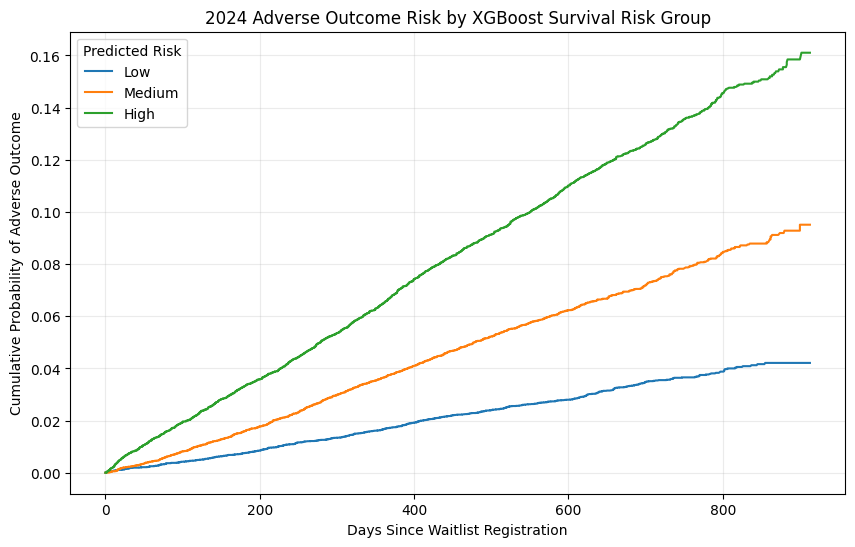


TOP 20 XGBOOST SURVIVAL FEATURES

                    Feature  Importance
                    AGE_10Y      0.1606
        FUNC_GROUP_Moderate      0.1140
            FUNC_GROUP_Poor      0.0965
A2A2B_status_B - recorded 1      0.0611
                   REGION_5      0.0558
                   ETHCAT_5      0.0498
              ON_DIALYSIS_Y      0.0427
                   REGION_4      0.0420
                   ETHCAT_2      0.0311
             INIT_STAT_4099      0.0294
                   ETHCAT_4      0.0254
                  REGION_10      0.0239
                BMI_missing      0.0219
                  REGION_11      0.0216
                   GENDER_M      0.0216
                   REGION_3      0.0177
                      ABO_A      0.0173
   A2A2B_status_B - missing      0.0160
           FUNC_GROUP_Other      0.0145
                     ABO_AB      0.0131

XGBOOST SURVIVAL IMPORTANCE BY ORIGINAL VARIABLE

Original_Variable  Importance  Importance_Percent
       FUNC_GROUP      0

In [8]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 6
#
# FINAL RISK-GROUP VALIDATION
# + COMPETING-RISK OUTCOMES
# + XGBOOST SURVIVAL EXPLAINABILITY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

from lifelines import AalenJohansenFitter


# ============================================================
# PART 1 — COMPETING-RISK INCIDENCE BY FINAL RISK GROUP
# ============================================================

time_points = [
    365,
    1095,
    1825
]

time_labels = [
    "1Y",
    "3Y",
    "5Y"
]


risk_group_cif_rows = []


for group_name in [
    "Low",
    "Medium",
    "High"
]:

    group_df = (
        final_survival_test[
            final_survival_test[
                "Risk_Group"
            ] == group_name
        ]
    )


    # --------------------------------------------------------
    # Adverse-event cumulative incidence
    # --------------------------------------------------------

    aj_adverse = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )


    aj_adverse.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=1
    )


    adverse_cif = (
        aj_adverse
        .cumulative_density_
        .iloc[:, 0]
    )


    # --------------------------------------------------------
    # Transplant cumulative incidence
    # --------------------------------------------------------

    aj_tx = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )


    aj_tx.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=2
    )


    tx_cif = (
        aj_tx
        .cumulative_density_
        .iloc[:, 0]
    )


    row = {
        "Risk_Group":
            group_name,

        "N":
            len(group_df)
    }


    # --------------------------------------------------------
    # Extract cumulative incidence at 1, 3, and 5 years
    # --------------------------------------------------------

    for t, label in zip(
        time_points,
        time_labels
    ):

        adverse_times = adverse_cif.index[
            adverse_cif.index <= t
        ]

        tx_times = tx_cif.index[
            tx_cif.index <= t
        ]


        if len(adverse_times) > 0:

            adverse_value = float(
                adverse_cif.loc[
                    adverse_times[-1]
                ]
            )

        else:

            adverse_value = 0.0


        if len(tx_times) > 0:

            tx_value = float(
                tx_cif.loc[
                    tx_times[-1]
                ]
            )

        else:

            tx_value = 0.0


        row[
            f"Adverse_{label}"
        ] = adverse_value

        row[
            f"Transplant_{label}"
        ] = tx_value


    risk_group_cif_rows.append(
        row
    )


risk_group_cif = pd.DataFrame(
    risk_group_cif_rows
)


print(
    "=========================================="
)

print(
    "FINAL 2024 COMPETING-RISK RESULTS "
    "BY MODEL RISK GROUP"
)

print(
    "==========================================\n"
)


print(
    risk_group_cif
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 2 — HOW MUCH HIGHER IS HIGH RISK VS LOW RISK?
# ============================================================

risk_lookup = (
    risk_group_cif
    .set_index(
        "Risk_Group"
    )
)


risk_separation = pd.DataFrame({

    "Time": [
        "1 Year",
        "3 Years",
        "5 Years"
    ],

    "Low Risk": [
        risk_lookup.loc[
            "Low",
            "Adverse_1Y"
        ],

        risk_lookup.loc[
            "Low",
            "Adverse_3Y"
        ],

        risk_lookup.loc[
            "Low",
            "Adverse_5Y"
        ]
    ],

    "High Risk": [
        risk_lookup.loc[
            "High",
            "Adverse_1Y"
        ],

        risk_lookup.loc[
            "High",
            "Adverse_3Y"
        ],

        risk_lookup.loc[
            "High",
            "Adverse_5Y"
        ]
    ]
})


risk_separation[
    "High_vs_Low_Ratio"
] = (
    risk_separation[
        "High Risk"
    ]
    /
    risk_separation[
        "Low Risk"
    ]
)


print(
    "\n=========================================="
)

print(
    "HIGH-RISK VS LOW-RISK SEPARATION"
)

print(
    "==========================================\n"
)


print(
    risk_separation
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 3 — PLOT ADVERSE CUMULATIVE INCIDENCE
# BY FINAL MODEL RISK GROUP
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for group_name in [
    "Low",
    "Medium",
    "High"
]:

    group_df = (
        final_survival_test[
            final_survival_test[
                "Risk_Group"
            ] == group_name
        ]
    )


    aj = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )


    aj.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=1
    )


    cif = (
        aj
        .cumulative_density_
        .iloc[:, 0]
    )


    plt.plot(
        cif.index,
        cif.values,
        label=group_name
    )


plt.title(
    "2024 Adverse Outcome Risk "
    "by XGBoost Survival Risk Group"
)

plt.xlabel(
    "Days Since Waitlist Registration"
)

plt.ylabel(
    "Cumulative Probability of Adverse Outcome"
)

plt.legend(
    title="Predicted Risk"
)

plt.grid(
    alpha=0.25
)

plt.show()


# ============================================================
# PART 4 — XGBOOST BUILT-IN FEATURE IMPORTANCE
# ============================================================

feature_names = (
    X_train_surv
    .columns
    .tolist()
)


xgb_feature_importance = pd.DataFrame({

    "Feature":
        feature_names,

    "Importance":
        xgb_survival
        .feature_importances_
})


xgb_feature_importance = (
    xgb_feature_importance

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n=========================================="
)

print(
    "TOP 20 XGBOOST SURVIVAL FEATURES"
)

print(
    "==========================================\n"
)


print(
    xgb_feature_importance
    .head(20)
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 5 — MAP PROCESSED FEATURES
# BACK TO ORIGINAL VARIABLES
# ============================================================

original_variables = [
    "AGE_10Y",
    "BMI_5",
    "BMI_missing",
    "GENDER",
    "ETHCAT",
    "ABO",
    "ON_DIALYSIS",
    "FUNC_GROUP",
    "INIT_STAT",
    "REGION",
    "A2A2B_status"
]


original_variables_sorted = sorted(
    original_variables,
    key=len,
    reverse=True
)


def map_original_variable(
    processed_name
):

    for variable in (
        original_variables_sorted
    ):

        if (
            processed_name == variable
            or
            processed_name.startswith(
                variable + "_"
            )
        ):

            return variable

    return "OTHER"


xgb_feature_importance[
    "Original_Variable"
] = (
    xgb_feature_importance[
        "Feature"
    ]
    .apply(
        map_original_variable
    )
)


aggregated_xgb_importance = (

    xgb_feature_importance

    .groupby(
        "Original_Variable",
        as_index=False
    )

    ["Importance"]

    .sum()

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


aggregated_xgb_importance[
    "Importance_Percent"
] = (

    aggregated_xgb_importance[
        "Importance"
    ]

    /

    aggregated_xgb_importance[
        "Importance"
    ].sum()

    * 100
)


print(
    "\n=========================================="
)

print(
    "XGBOOST SURVIVAL IMPORTANCE "
    "BY ORIGINAL VARIABLE"
)

print(
    "==========================================\n"
)


print(
    aggregated_xgb_importance
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 6 — SHAP-LIKE XGBOOST CONTRIBUTIONS
#
# XGBoost can directly return feature contributions.
#
# This avoids needing an extra SHAP package.
# ============================================================

rng = np.random.RandomState(
    42
)


sample_size = min(
    5000,
    len(X_test_surv)
)


sample_indices = rng.choice(
    len(X_test_surv),
    size=sample_size,
    replace=False
)


X_explain = (
    X_test_surv
    .iloc[
        sample_indices
    ]
)


# Convert to XGBoost matrix
d_explain = xgb.DMatrix(
    X_explain,
    feature_names=feature_names
)


# ------------------------------------------------------------
# pred_contribs returns:
#
# one value per feature
# + one final bias column
# ------------------------------------------------------------

contributions = (
    xgb_survival
    .get_booster()
    .predict(
        d_explain,
        pred_contribs=True
    )
)


# Remove final bias column
feature_contributions = (
    contributions[
        :,
        :-1
    ]
)


mean_abs_contribution = (
    np.abs(
        feature_contributions
    )
    .mean(
        axis=0
    )
)


contribution_table = pd.DataFrame({

    "Feature":
        feature_names,

    "Mean_Absolute_Contribution":
        mean_abs_contribution
})


contribution_table[
    "Original_Variable"
] = (
    contribution_table[
        "Feature"
    ]
    .apply(
        map_original_variable
    )
)


contribution_original = (

    contribution_table

    .groupby(
        "Original_Variable",
        as_index=False
    )

    [
        "Mean_Absolute_Contribution"
    ]

    .sum()

    .sort_values(
        "Mean_Absolute_Contribution",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


contribution_original[
    "Relative_Contribution_Percent"
] = (

    contribution_original[
        "Mean_Absolute_Contribution"
    ]

    /

    contribution_original[
        "Mean_Absolute_Contribution"
    ].sum()

    * 100
)


print(
    "\n=========================================="
)

print(
    "FINAL MODEL EXPLAINABILITY "
    "BY ORIGINAL VARIABLE"
)

print(
    "==========================================\n"
)


print(
    contribution_original
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 7 — DIRECTION OF AGE CONTRIBUTION
# ============================================================

age_index = (
    feature_names
    .index(
        "AGE_10Y"
    )
)


age_contribution = (
    feature_contributions[
        :,
        age_index
    ]
)


age_values = (
    test_ps
    .iloc[
        sample_indices
    ]
    [
        "INIT_AGE"
    ]
    .to_numpy()
)


age_direction = pd.DataFrame({

    "Age":
        age_values,

    "Age_Contribution":
        age_contribution
})


age_direction[
    "Age_Group"
] = pd.cut(

    age_direction[
        "Age"
    ],

    bins=[
        -np.inf,
        17,
        34,
        49,
        64,
        np.inf
    ],

    labels=[
        "0-17",
        "18-34",
        "35-49",
        "50-64",
        "65+"
    ]
)


age_direction_summary = (

    age_direction

    .groupby(
        "Age_Group",
        observed=True
    )

    .agg(

        N=(
            "Age_Contribution",
            "size"
        ),

        Mean_Age=(
            "Age",
            "mean"
        ),

        Mean_Contribution=(
            "Age_Contribution",
            "mean"
        )
    )

    .reset_index()
)


print(
    "\n=========================================="
)

print(
    "AGE EFFECT ON XGBOOST SURVIVAL RISK"
)

print(
    "==========================================\n"
)


print(
    age_direction_summary
    .round(4)
    .to_string(index=False)
)


print(
    "\nPositive contribution = pushes predicted hazard higher."
)

print(
    "Negative contribution = pushes predicted hazard lower."
)


# ============================================================
# FINAL
# ============================================================

print(
    "\n=========================================="
)

print(
    "CHUNK 6 COMPLETE"
)

print(
    "=========================================="
)

In [9]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — SURVIVAL MODELING
# CHUNK 7 — FINAL RESULTS, SAVE OUTPUTS, EXPORT ZIP
# ============================================================

import os
import json
import joblib
import shutil
import pandas as pd
import numpy as np

from lifelines import AalenJohansenFitter
from google.colab import files


# ============================================================
# PART 1 — FINAL 1-YEAR COMPETING-RISK EVALUATION
#
# IMPORTANT:
# The 2024 test cohort does NOT have enough follow-up
# for valid 3-year or 5-year predictive evaluation.
#
# Therefore the final test-horizon result is 1 year.
# ============================================================

final_1yr_rows = []


for group_name in [
    "Low",
    "Medium",
    "High"
]:

    group_df = (
        final_survival_test[
            final_survival_test[
                "Risk_Group"
            ] == group_name
        ]
    )


    # --------------------------------------------------------
    # Adverse cumulative incidence
    # --------------------------------------------------------

    aj_adverse = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )


    aj_adverse.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=1
    )


    adverse_cif = (
        aj_adverse
        .cumulative_density_
        .iloc[:, 0]
    )


    adverse_available = (
        adverse_cif.index[
            adverse_cif.index <= 365
        ]
    )


    if len(adverse_available) > 0:

        adverse_1y = float(
            adverse_cif.loc[
                adverse_available[-1]
            ]
        )

    else:

        adverse_1y = 0.0


    # --------------------------------------------------------
    # Transplant cumulative incidence
    # --------------------------------------------------------

    aj_transplant = AalenJohansenFitter(
        jitter_level=0.0001,
        seed=42
    )


    aj_transplant.fit(
        durations=group_df[
            TIME_COL
        ],

        event_observed=group_df[
            "event_type"
        ],

        event_of_interest=2
    )


    transplant_cif = (
        aj_transplant
        .cumulative_density_
        .iloc[:, 0]
    )


    transplant_available = (
        transplant_cif.index[
            transplant_cif.index <= 365
        ]
    )


    if len(transplant_available) > 0:

        transplant_1y = float(
            transplant_cif.loc[
                transplant_available[-1]
            ]
        )

    else:

        transplant_1y = 0.0


    final_1yr_rows.append({

        "Risk_Group":
            group_name,

        "N":
            len(group_df),

        "Adverse_1Y_CIF":
            adverse_1y,

        "Transplant_1Y_CIF":
            transplant_1y
    })


final_1yr_risk_groups = (
    pd.DataFrame(
        final_1yr_rows
    )
)


print(
    "=========================================="
)

print(
    "FINAL 2024 ONE-YEAR RISK-GROUP RESULTS"
)

print(
    "==========================================\n"
)


print(
    final_1yr_risk_groups
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 2 — FINAL RISK SEPARATION
# ============================================================

final_1yr_lookup = (
    final_1yr_risk_groups
    .set_index(
        "Risk_Group"
    )
)


low_1yr = (
    final_1yr_lookup.loc[
        "Low",
        "Adverse_1Y_CIF"
    ]
)


medium_1yr = (
    final_1yr_lookup.loc[
        "Medium",
        "Adverse_1Y_CIF"
    ]
)


high_1yr = (
    final_1yr_lookup.loc[
        "High",
        "Adverse_1Y_CIF"
    ]
)


high_vs_low_ratio = (
    high_1yr
    /
    low_1yr
)


print(
    "\nFINAL 1-YEAR RISK SEPARATION"
)

print(
    "\nLow-risk adverse incidence:",
    round(
        low_1yr,
        4
    )
)

print(
    "Medium-risk adverse incidence:",
    round(
        medium_1yr,
        4
    )
)

print(
    "High-risk adverse incidence:",
    round(
        high_1yr,
        4
    )
)

print(
    "High vs Low ratio:",
    round(
        high_vs_low_ratio,
        2
    ),
    "x"
)


# ============================================================
# PART 3 — FINAL MODEL PERFORMANCE TABLE
# ============================================================

final_survival_performance = pd.DataFrame({

    "Model": [
        "Cox PH",
        "XGBoost Survival"
    ],

    "Validation_2023_C_Index": [
        cox_val_cindex,
        xgb_val_cindex
    ],

    "Test_2024_C_Index": [
        cox_test_cindex,
        xgb_test_cindex
    ],

    "Selected": [
        False,
        True
    ]
})


print(
    "\n=========================================="
)

print(
    "FINAL SURVIVAL MODEL PERFORMANCE"
)

print(
    "==========================================\n"
)


print(
    final_survival_performance
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 4 — FINAL IMPORTANT COX RESULTS
#
# Cox is kept as the interpretable adjusted model.
# XGBoost Survival is the final predictive model.
# ============================================================

final_cox_results = (
    main_hr.copy()
)


print(
    "\n=========================================="
)

print(
    "FINAL INTERPRETABLE COX RESULTS"
)

print(
    "==========================================\n"
)


print(
    final_cox_results
    .round(4)
    .to_string(index=False)
)


# ============================================================
# PART 5 — CREATE OUTPUT DIRECTORY
# ============================================================

output_dir = (
    "/content/"
    "medimate_survival_modeling_outputs"
)


os.makedirs(
    output_dir,
    exist_ok=True
)


# ============================================================
# PART 6 — SAVE MODELS
# ============================================================

# Interpretable Cox model
joblib.dump(
    clean_cox,
    os.path.join(
        output_dir,
        "final_cox_model.joblib"
    )
)


# Final XGBoost survival model
joblib.dump(
    xgb_survival,
    os.path.join(
        output_dir,
        "final_xgboost_survival_model.joblib"
    )
)


xgb_survival.save_model(
    os.path.join(
        output_dir,
        "final_xgboost_survival_model.json"
    )
)


# ============================================================
# PART 7 — SAVE TABLES
# ============================================================

final_survival_performance.to_csv(
    os.path.join(
        output_dir,
        "survival_model_comparison.csv"
    ),
    index=False
)


final_1yr_risk_groups.to_csv(
    os.path.join(
        output_dir,
        "final_1yr_risk_groups.csv"
    ),
    index=False
)


final_cox_results.to_csv(
    os.path.join(
        output_dir,
        "final_cox_hazard_ratios.csv"
    ),
    index=False
)


aggregated_xgb_importance.to_csv(
    os.path.join(
        output_dir,
        "xgboost_survival_feature_importance.csv"
    ),
    index=False
)


contribution_original.to_csv(
    os.path.join(
        output_dir,
        "xgboost_survival_explainability.csv"
    ),
    index=False
)


age_direction_summary.to_csv(
    os.path.join(
        output_dir,
        "xgboost_survival_age_direction.csv"
    ),
    index=False
)


# Save earlier descriptive competing-risk results
competing_risk_summary.to_csv(
    os.path.join(
        output_dir,
        "overall_competing_risk_summary.csv"
    ),
    index=False
)


age_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_age.csv"
    ),
    index=False
)


dialysis_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_dialysis.csv"
    ),
    index=False
)


gender_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_gender.csv"
    ),
    index=False
)


abo_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_blood_type.csv"
    ),
    index=False
)


ethcat_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_ethcat.csv"
    ),
    index=False
)


func_survival.to_csv(
    os.path.join(
        output_dir,
        "competing_risk_functional_status.csv"
    ),
    index=False
)


# ============================================================
# PART 8 — SAVE PATIENT-SAFE TEST PREDICTIONS
#
# Contains IDs, risk scores and risk groups.
#
# IMPORTANT:
# This contains patient-level information and should remain
# private under the project data-use agreement.
# ============================================================

final_survival_test.to_csv(
    os.path.join(
        output_dir,
        "private_test_risk_predictions.csv.gz"
    ),
    index=False,
    compression="gzip"
)


# ============================================================
# PART 9 — SAVE FINAL SETTINGS
# ============================================================

final_settings = {

    "project":
        "MediMate Kidney Waitlist Survival Modeling",

    "primary_predictive_model":
        "XGBoost Survival Cox",

    "interpretability_model":
        "Cox Proportional Hazards",

    "event_of_interest":
        "death or removal for being too sick",

    "competing_event":
        "transplant",

    "training_years":
        "2015-2022",

    "validation_year":
        2023,

    "test_year":
        2024,

    "patient_safe_split":
        True,

    "patient_overlap_train_validation":
        0,

    "patient_overlap_train_test":
        0,

    "patient_overlap_validation_test":
        0,

    "cpra_used":
        False,

    "cox_validation_c_index":
        float(
            cox_val_cindex
        ),

    "cox_test_c_index":
        float(
            cox_test_cindex
        ),

    "xgb_validation_c_index":
        float(
            xgb_val_cindex
        ),

    "xgb_test_c_index":
        float(
            xgb_test_cindex
        ),

    "final_test_horizon_days":
        365,

    "low_risk_1yr_adverse_cif":
        float(
            low_1yr
        ),

    "medium_risk_1yr_adverse_cif":
        float(
            medium_1yr
        ),

    "high_risk_1yr_adverse_cif":
        float(
            high_1yr
        ),

    "high_vs_low_1yr_ratio":
        float(
            high_vs_low_ratio
        ),

    "note":
        (
            "2024 test predictions are evaluated "
            "primarily at 1 year because the cohort "
            "does not have sufficient follow-up for "
            "3-year or 5-year predictive evaluation."
        )
}


with open(
    os.path.join(
        output_dir,
        "final_survival_settings.json"
    ),
    "w"
) as f:

    json.dump(
        final_settings,
        f,
        indent=4
    )


# ============================================================
# PART 10 — LIST SAVED FILES
# ============================================================

saved_files = sorted(
    os.listdir(
        output_dir
    )
)


print(
    "\n=========================================="
)

print(
    "SAVED SURVIVAL OUTPUTS"
)

print(
    "==========================================\n"
)


for i, filename in enumerate(
    saved_files,
    start=1
):

    print(
        f"{i}. {filename}"
    )


print(
    "\nTotal files:",
    len(saved_files)
)


# ============================================================
# PART 11 — CREATE ZIP
# ============================================================

zip_base = (
    "/content/"
    "medimate_survival_modeling_outputs"
)


zip_path = shutil.make_archive(
    zip_base,
    "zip",
    output_dir
)


zip_size_mb = (
    os.path.getsize(
        zip_path
    )
    /
    (
        1024 ** 2
    )
)


print(
    "\n=========================================="
)

print(
    "ZIP CREATED"
)

print(
    "=========================================="
)


print(
    "\nFile:",
    zip_path
)

print(
    "Size:",
    round(
        zip_size_mb,
        2
    ),
    "MB"
)


# ============================================================
# PART 12 — FINAL NOTEBOOK CONCLUSION
# ============================================================

print(
    """
============================================================
FINAL SURVIVAL MODELING CONCLUSION
============================================================

Purpose
-------
The goal was to study how long kidney waitlist patients remain
at risk before an adverse outcome and to predict which patients
have higher adverse-outcome risk over time.

Competing Risks
---------------
Transplant is a major competing event. Because a transplanted
patient is no longer at risk of an adverse outcome on the same
waitlist registration, the main descriptive analysis used
Aalen-Johansen competing-risk estimates.

Overall Results
---------------
At 1 year, the overall adverse cumulative incidence was about
3.9%, while about 30% of registrations had resulted in transplant.

The ordinary Kaplan-Meier estimate was higher because it treats
transplant as censoring. Therefore competing-risk estimates are
more appropriate for describing actual adverse-outcome probability.

Subgroup Findings
-----------------
Adverse risk increased strongly with age and poorer functional
status. Differences were also observed across dialysis status,
blood type, ETHCAT, gender and region.

These are associations and should not be interpreted as causal.

Adjusted Cox Model
------------------
A patient-safe Cox model was built using older registrations for
training, 2023 for validation and 2024 for testing.

Important adjusted findings included:

- Higher age was associated with higher adverse-event hazard.
- Dialysis was associated with higher adverse-event hazard.
- Moderate functional status had higher hazard than good status.
- Poor functional status had substantially higher hazard than
  good functional status.

The Cox model achieved a validation C-index of about 0.664 and a
2024 test C-index of about 0.669.

Final Predictive Model
----------------------
XGBoost Survival performed better than the Cox model.

Validation C-index: about 0.674
2024 test C-index: about 0.678

Because model selection was based on validation performance,
XGBoost Survival was selected as the final survival prediction
model.

Risk Stratification
-------------------
On the 2024 test cohort, the model separated patients into clear
risk groups.

At 1 year:

Low risk: about 1.7% adverse cumulative incidence
Medium risk: about 3.7%
High risk: about 6.6%

The high-risk group had about 3.9 times the 1-year adverse
incidence of the low-risk group.

Explainability
--------------
Age was the strongest overall contributor to the XGBoost
survival predictions.

Functional status, region, ETHCAT and dialysis status also made
important contributions.

Older age pushed predicted hazard higher, while younger age
generally pushed predicted hazard lower.

Important Limitations
---------------------
The model does not include every possible clinical factor.

Transplant is a competing event, so ordinary survival estimates
alone are not enough.

Some subgroup differences may reflect differences in patient
characteristics, geography, access or other factors not included
in the model.

The 2024 test cohort does not have enough follow-up for reliable
3-year or 5-year predictive evaluation. The main final test
horizon is therefore 1 year.

Model explanations describe model behavior and associations,
not causal effects.

This model is for research and risk stratification. It should not
be used by itself to make clinical or organ-allocation decisions.

============================================================
SURVIVAL MODELING COMPLETE
============================================================
"""
)


# ============================================================
# PART 13 — DOWNLOAD ZIP
# ============================================================

files.download(
    zip_path
)

/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
         

FINAL 2024 ONE-YEAR RISK-GROUP RESULTS

Risk_Group     N  Adverse_1Y_CIF  Transplant_1Y_CIF
       Low 16521          0.0170             0.3320
    Medium 16520          0.0371             0.2965
      High 16521          0.0660             0.3857

FINAL 1-YEAR RISK SEPARATION

Low-risk adverse incidence: 0.017
Medium-risk adverse incidence: 0.0371
High-risk adverse incidence: 0.066
High vs Low ratio: 3.87 x

FINAL SURVIVAL MODEL PERFORMANCE

           Model  Validation_2023_C_Index  Test_2024_C_Index  Selected
          Cox PH                   0.6644             0.6690     False
XGBoost Survival                   0.6737             0.6784      True

FINAL INTERPRETABLE COX RESULTS

            Feature  Hazard_Ratio  HR_Lower_95  HR_Upper_95  P_Value
            AGE_10Y        1.3053       1.2976       1.3132   0.0000
              BMI_5        0.9857       0.9792       0.9923   0.0000
        BMI_missing        1.4203       1.2722       1.5857   0.0000
           GENDER_M        1.0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>